# 01 · EDA: Who buys the concert ticket?

**ML DSBA M2 · Kaggle challenge "Front Row: Who Buys the Ticket?"**



**How to read it.** Every section ends with a small box:

> **What I take from this** → what the plots actually mean
> **→ Feature ideas** → what we should build from it

Section 13 collects all the feature ideas into one plan. If you're short on time, read the summary below and then jump to section 13.


## sum

1. **Shape of the problem.** One row = one user × one concert. Train has 6,000 users × 5 concerts = 30,000 rows, test has 4,000 *different* users × 5 = 20,000 rows. Same 5 concerts for everybody. Since train and test never share a user, our CV has to be grouped by `user_id`.


2. **Target and metric.** 33.6% of rows are `buy = 1`. The score is pooled F1 on the positive class with hard 0/1 labels. Predicting "everyone buys" already gets F1 ≈ 0.50, and "nobody buys" gets 0. So the decision threshold is part of the model.
3. **The CSV alone is weak.** Most raw columns (age, price, city...) barely move the buy rate; only the "money" ones (spending band, typical spend) do. What works are **combinations**: a travel search to the venue city arriving within ±1 day of the concert (~74% buy vs ~10% when the date is off), ticket cost compared to what the user usually pays (~41% → ~19%), and timing compared to the user's usual booking lead.
4. **The listening history is where the signal is.** Among users with active listening data, people who never played the concert's artist buy only ~7% of the time. When that artist is their #1 among the five, it's ~69%. Recency matters a lot too.
5. **A blank is not a zero.** Users with no linked app, an `empty` account or a `missing` account buy ~50% of the time vs ~31% for active users. First-timers have no spend history by construction.
6. **Train and test look alike**: adversarial validation AUC ≈ 0.49 with folds grouped by user. With ungrouped folds it's 0.61, purely because the model recognises users across folds. Nice proof that **grouping by user is not optional**.

## Contents

1. Setup
2. The problem in one picture
3. First look at the files
4. The target: who actually buys?
5. Missing values: what a blank means
6. Who are the users? (profile)
7. The offer: price and timing
8. Geography: how far is the concert?
9. Engagement: page visits, wishlist, travel searches
10. The music app JSON (the big one)
11. All signals side by side
12. Do train and test look the same?
13. Summary and feature engineering plan

---
## 1. Setup

.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:.3f}".format)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"

BLUE, GREY, RED, GREEN = "#3b6ea8", "#b5b5b5", "#d1495b", "#2a9d8f"

DATA_DIR = Path("ml-dsba-m-2")
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
sample_sub = pd.read_csv(DATA_DIR / "sample_submission.csv")

SNAPSHOT = pd.Timestamp("2026-10-01", tz="UTC")   # prediction time
OVERALL = train["buy"].mean()                      # baseline buy rate, used as reference line everywhere
print(f"train {train.shape} | test {test.shape} | sample_sub {sample_sub.shape}")
print(f"overall buy rate in train: {OVERALL:.3f}")

/Users/apple/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


train (30000, 32) | test (20000, 31) | sample_sub (20000, 2)
overall buy rate in train: 0.336


Two small helpers I'll use all over the notebook. The idea is always the same question: **"if I split the rows by this column, does the buy rate change?"** If the bars stay around the red dashed line (the overall 33.6%), the column alone tells us nothing. If they move a lot, there's signal.

The `n=` on top of each bar is how many rows are in that group, so we don't get excited about a bar built on 12 rows. A grey bar is the group of rows where the value is **blank** (NaN).

In [2]:
def _label(v):
    # nicer labels for pd.cut / pd.qcut intervals
    if isinstance(v, pd.Interval):
        return f"{v.left:,.4g} to {v.right:,.4g}"
    return str(v)


def rate_plot(data, col, bins=None, q=None, keep_missing=True, ax=None, title=None,
              xlabel=None, rot=0, order=None, target="buy", annotate=True, labels=None, blank_label="blank"):
    # bar chart of buy rate per group of `col`, with group sizes on top
    s = data[col]
    binned = bins is not None or q is not None
    if q is not None:
        s = pd.qcut(s, q, duplicates="drop")
    elif bins is not None:
        s = pd.cut(s, bins, labels=labels)

    if binned:
        cats = [_label(c) for c in s.cat.categories]
        lab = s.astype(object).map(lambda v: _label(v) if isinstance(v, pd.Interval) else v)
    else:
        lab = s.astype(object)
        cats = order if order is not None else sorted(lab.dropna().unique(), key=lambda v: (str(type(v)), v))
    lab = lab.where(s.notna(), blank_label)
    if keep_missing and (lab == blank_label).any():
        cats = list(cats) + [blank_label]

    tab = (data.assign(_g=lab).groupby("_g")[target].agg(n="size", rate="mean")
           .reindex(cats).dropna(subset=["n"]))

    if ax is None:
        _, ax = plt.subplots(figsize=(max(5, 0.75 * len(tab) + 2), 3.6))
    colors = [GREY if str(i) == blank_label else BLUE for i in tab.index]
    ax.bar(range(len(tab)), tab["rate"], color=colors)
    ax.axhline(OVERALL if target == "buy" else data[target].mean(), ls="--", color=RED, lw=1.2)
    ax.set_xticks(range(len(tab)))
    ax.set_xticklabels([str(i) for i in tab.index], rotation=rot, ha="right" if rot else "center")
    ax.set_ylim(0, min(1.0, tab["rate"].max() * 1.28 + 0.02))
    ax.set_ylabel("buy rate")
    ax.set_xlabel(col if xlabel is None else xlabel)
    ax.set_title(title or f"Buy rate by {col}")
    if annotate:
        for i, (n, r) in enumerate(zip(tab["n"], tab["rate"])):
            ax.text(i, r + 0.01, f"{r:.0%}\nn={int(n):,}", ha="center", va="bottom", fontsize=7.5)
    return tab


def rate_table(data, by, target="buy"):
    # same idea as rate_plot but just the numbers
    return data.groupby(by, observed=True, dropna=False)[target].agg(n="size", rate="mean")

---
## 2. The problem in one picture

Before looking at any column I want the **timeline** clear in my head, because the whole task is about *when* things happen:

- the music app history covers **3 July → 30 September 2026**
- presale opened on **28 September**
- we predict at the **snapshot, 1 October 00:00 UTC**
- `buy = 1` means the user buys at least one ticket for that concert between **1 and 8 October** (8 Oct excluded)
- the five concerts themselves happen later, from 25 October to 28 December

So everything we're given is **before** the snapshot, and we're predicting a 7-day window **right after** it. This is the classic "use the past to predict the next week" setup.

,concert_id,artist_name,venue_city,concert_at,genres,days_after_snapshot
0,C01,Kendrick Lamar,Paris,2026-10-25 20:00:00+00:00,hip_hop|rnb_soul|jazz_funk|pop,24
1,C02,Olivia Rodrigo,Lyon,2026-11-10 20:00:00+00:00,pop|pop_rock|alternative,40
2,C03,Taylor Swift,Bordeaux,2026-11-26 20:00:00+00:00,pop|pop_rock|alternative|folk_country,56
3,C04,Tame Impala,Lille,2026-12-12 20:00:00+00:00,pop|alternative|electronic|psychedelic,72
4,C05,SZA,Nantes,2026-12-28 20:00:00+00:00,hip_hop|rnb_soul|jazz_funk|pop|alternative,88


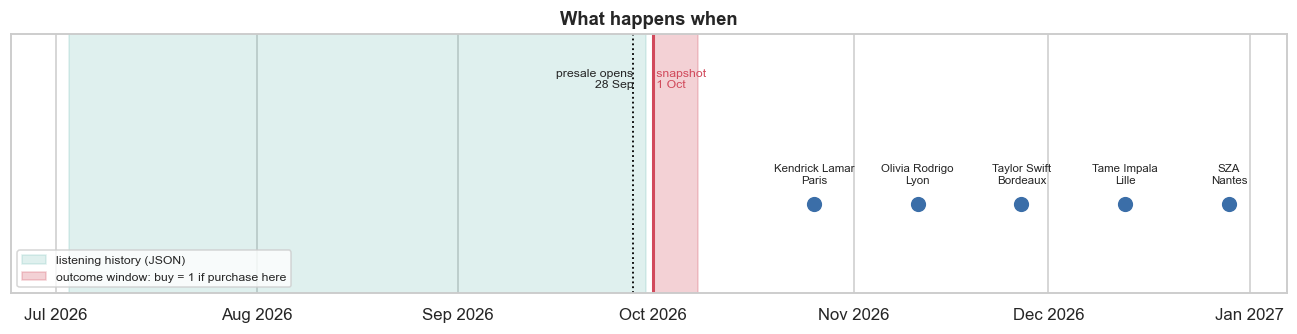

In [3]:
concerts = (train.drop_duplicates("concert_id")
            [["concert_id", "artist_name", "venue_city", "concert_at", "genres"]]
            .sort_values("concert_id").reset_index(drop=True))
concerts["concert_at"] = pd.to_datetime(concerts["concert_at"])
concerts["days_after_snapshot"] = (concerts["concert_at"] - SNAPSHOT).dt.days
display(concerts)

fig, ax = plt.subplots(figsize=(12, 3.2))
d = lambda s: pd.Timestamp(s)
ax.axvspan(d("2026-07-03"), d("2026-09-30"), color=GREEN, alpha=0.15, label="listening history (JSON)")
ax.axvspan(d("2026-10-01"), d("2026-10-08"), color=RED, alpha=0.25, label="outcome window: buy = 1 if purchase here")
ax.axvline(d("2026-09-28"), color="black", ls=":", lw=1.2)
ax.text(d("2026-09-28"), 1.02, "presale opens\n28 Sep", ha="right", va="bottom", fontsize=8)
ax.axvline(d("2026-10-01"), color=RED, lw=2)
ax.text(d("2026-10-01"), 1.02, " snapshot\n 1 Oct", ha="left", va="bottom", fontsize=8, color=RED)
for _, r in concerts.iterrows():
    t = r["concert_at"].tz_localize(None)
    ax.scatter(t, 0.45, s=80, color=BLUE, zorder=3)
    ax.text(t, 0.55, f"{r['artist_name']}\n{r['venue_city']}", ha="center", fontsize=7.5)
ax.set_ylim(0, 1.3); ax.set_yticks([])
ax.xaxis.set_major_locator(mdates.MonthLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend(loc="lower left", fontsize=8, frameon=True)
ax.set_title("What happens when")
plt.tight_layout(); plt.show()

> **What I take from this**
> - The concerts are 24 to 88 days away at the snapshot. Kendrick in Paris is the closest (24 days), SZA in Nantes the furthest (88 days).
> - Presale opened 3 days before the snapshot, so people have just started buying. Our window is the first full week after that.
> - The outcome is about **this specific week**, not "will this person ever go". That's why timing features (how far the concert is vs. how early this person usually books) can matter.

---
## 3. First look at the files

We have four files:

| file | what it is |
|---|---|
| `train.csv` | 30,000 labelled rows (user × concert) |
| `test.csv` | 20,000 rows, same columns minus `buy` |
| `music_app.json` | nested listening history for linked accounts (section 10) |
| `sample_submission.csv` | `row_id,buy` format, all zeros (which scores F1 = 0!) |

In [5]:
train.head(3).T  # plz note that i transpose the dataset here

,0,1,2
row_id,R2F019957,R0804D93A,R367FE81E
user_id,U2CFDCAAD,U1FC01010,U0C605712
music_app_user_id,M1B01D2D7,M1B2C63CC,M3AEF638D
age,23,51,32
education,postgraduate,undergraduate,secondary
spending_capacity_band,2,5,1
home_city,Nantes,Bordeaux,Lyon
home_lat,47.218,44.838,45.764
home_lon,-1.554,-0.579,4.835
stated_favourite_genre,pop,pop,classical


That's a lot of columns, so I grouped them by **what they describe**. This grouping is also roughly how I'd split the feature work between us.

In [6]:
FIELD_GROUPS = {
    "IDs": ["row_id", "user_id", "music_app_user_id"],
    "User profile": ["age", "education", "spending_capacity_band", "home_city", "home_lat", "home_lon",
                     "stated_favourite_genre"],
    "Purchase history": ["past_purchase_count", "first_timer", "typical_ticket_spend", "usual_booking_lead_days"],
    "The offer": ["concert_id", "artist_id", "artist_name", "genres", "venue_city", "venue_lat", "venue_lon",
                  "concert_at", "ticket_price", "booking_fee", "discount_pct"],
    "Timestamps": ["sale_opened_at", "prediction_at"],
    "Recent engagement": ["event_page_visits_7d", "wishlisted", "travel_search_city", "travel_search_arrival"],
    "Target": ["buy"],
}
rows = []
for grp, cols in FIELD_GROUPS.items():
    for c in cols:
        rows.append({"group": grp, "column": c, "dtype": str(train[c].dtype),
                     "n_unique": train[c].nunique(), "missing_%": round(100 * train[c].isna().mean(), 1),
                     "example": train[c].dropna().iloc[0]})
pd.DataFrame(rows)

,group,column,dtype,n_unique,missing_%,example
0,IDs,row_id,object,30000,0.000,R2F019957
1,IDs,user_id,object,6000,0.000,U2CFDCAAD
2,IDs,music_app_user_id,object,5661,5.600,M1B01D2D7
3,User profile,age,int64,48,0.000,23
4,User profile,education,object,3,0.000,postgraduate
5,User profile,spending_capacity_band,int64,5,0.000,2
6,User profile,home_city,object,8,0.000,Nantes
7,User profile,home_lat,float64,8,0.000,47.218
8,User profile,home_lon,float64,8,0.000,-1.554
9,User profile,stated_favourite_genre,object,11,15.400,pop


### Sanity checks

Kaggle data is usually clean, but I still want to confirm a few structural things before trusting anything:

In [7]:
checks = {
    "row_id unique in train": train["row_id"].is_unique,
    "row_id unique in test": test["row_id"].is_unique,
    "every train user has exactly 5 rows": train.groupby("user_id").size().eq(5).all(),
    "every test user has exactly 5 rows": test.groupby("user_id").size().eq(5).all(),
    "each user sees each concert once (train)": train.groupby(["user_id", "concert_id"]).size().eq(1).all(),
    "users shared between train and test": len(set(train["user_id"]) & set(test["user_id"])),
    "sample_submission row_ids == test row_ids (same order)": sample_sub["row_id"].equals(test["row_id"]),
    "one music_app_user_id per user (train)": train.dropna(subset=["music_app_user_id"])
                                                  .groupby("user_id")["music_app_user_id"].nunique().eq(1).all(),
}
for k, v in checks.items():
    print(f"{k:<58} {v}")

const_cols = [c for c in train.columns if train[c].nunique(dropna=False) == 1]
print("\ncolumns with a single value in train:", const_cols)
print("same in test:", {c: test[c].unique().tolist() for c in const_cols})

row_id unique in train                                     True
row_id unique in test                                      True
every train user has exactly 5 rows                        True
every test user has exactly 5 rows                         True
each user sees each concert once (train)                   True
users shared between train and test                        0
sample_submission row_ids == test row_ids (same order)     True
one music_app_user_id per user (train)                     True

columns with a single value in train: ['sale_opened_at', 'prediction_at']
same in test: {'sale_opened_at': ['2026-09-28T00:00:00Z'], 'prediction_at': ['2026-10-01T00:00:00Z']}


> **What I take from this**
> - The structure is exactly what the description says: 5 rows per user, one per concert, and **zero user overlap** between train and test.
> - That has a big consequence for validation. If we use a normal `KFold`, the same person's 5 rows get split between train and validation folds. The model then sees "Calvin bought Taylor Swift" while being tested on "Calvin and SZA", and the score looks better than it really is. On Kaggle, every user is brand new. So: **`GroupKFold` with `groups=user_id`**, always.
> - `sale_opened_at` and `prediction_at` are the same for every row, so on their own they carry zero information. We drop them (but we use `prediction_at` to compute "days until the concert").
>
> **→ Feature ideas**
> - drop `sale_opened_at`, `prediction_at`, `row_id` as model inputs
> - `days_to_concert` = `concert_at` − `prediction_at` (only 5 values, one per concert, but useful in combination)

---
## 4. The target: who actually buys?

First thing I always look at: how often does `buy = 1` happen? That decides what a "good" score even looks like.

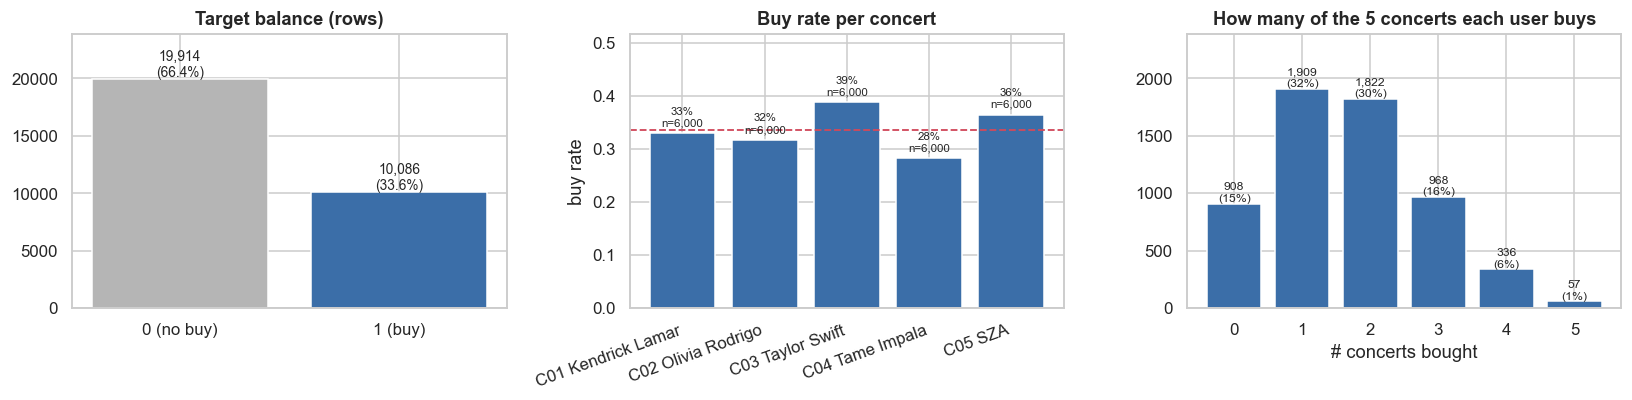

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

vc = train["buy"].value_counts().sort_index()
axes[0].bar(["0 (no buy)", "1 (buy)"], vc.values, color=[GREY, BLUE])
for i, v in enumerate(vc.values):
    axes[0].text(i, v, f"{v:,}\n({v / len(train):.1%})", ha="center", va="bottom", fontsize=9)
axes[0].set_ylim(0, vc.max() * 1.2); axes[0].set_title("Target balance (rows)")

train["concert_label"] = train["concert_id"] + " " + train["artist_name"]
test["concert_label"] = test["concert_id"] + " " + test["artist_name"]
rate_plot(train, "concert_label", ax=axes[1], title="Buy rate per concert", xlabel="", rot=20)

per_user = train.groupby("user_id")["buy"].sum().value_counts().sort_index()
axes[2].bar(per_user.index.astype(str), per_user.values, color=BLUE)
for i, v in zip(per_user.index, per_user.values):
    axes[2].text(i, v, f"{v:,}\n({v / per_user.sum():.0%})", ha="center", va="bottom", fontsize=8)
axes[2].set_ylim(0, per_user.max() * 1.25)
axes[2].set_title("How many of the 5 concerts each user buys"); axes[2].set_xlabel("# concerts bought")
plt.tight_layout(); plt.show()

A third of rows are buys. Not super rare, but not balanced either. And it's **not** "each user picks one concert": most users buy 1 or 2, some buy 0, a few buy all five. So each row really is its own yes/no decision.

### What this means for the metric

The leaderboard uses **pooled F1** with `buy = 1` as the positive class, over all 20,000 test rows together.

In plain words, F1 only cares about the buyers:
- **precision**: of the people we said "will buy", how many actually bought?
- **recall**: of the people who actually bought, how many did we catch?
- F1 is the harmonic mean of the two. Correctly predicting "won't buy" (true negatives) gives **no credit at all**.

Formula: $F1 = \dfrac{2\,TP}{2\,TP + FP + FN}$

Quick reference points so we know what "bad" looks like:

In [9]:
p = OVERALL
ref = pd.DataFrame({
    "strategy": ["predict all 0 (sample_submission)", "random guess with 33.6% ones", "predict all 1"],
    "expected F1": [0.0, p, 2 * p / (1 + p)],
    "why": ["no TP at all", "precision = recall = base rate", "recall = 1, precision = base rate"],
})
ref

,strategy,expected F1,why
0,predict all 0 (sample_submission),0.000,no TP at all
1,random guess with 33.6% ones,0.336,precision = recall = base rate
2,predict all 1,0.503,"recall = 1, precision = base rate"


> **What I take from this**
> - Any model we submit has to beat **F1 ≈ 0.50**, which is what you get by saying "everyone buys". Accuracy would be misleading here: "nobody buys" has 66% accuracy but F1 = 0.
> - Because F1 ignores true negatives and the positive class is the minority, the best cut-off is usually **below 0.5**. We should pick the threshold on out-of-fold predictions, not leave sklearn's default.
> - The per-concert rates differ (28% Tame Impala → 39% Taylor Swift), so the concert itself carries a bit of signal. But we're told not to use real-world info about the artists, so the only legit way to use this is through the data (concert ID, price, distance, listening...).
>
> **→ Feature ideas**
> - `concert_id` as a categorical feature (one-hot for linear models)
> - modelling decision: **tune the threshold for F1**, report it in the report as a hyperparameter

---
## 5. Missing values: what a blank means

The competition page literally says *"A blank is not a zero"*, so this section is worth doing carefully. For every column with blanks I want to know: **how many**, **why** (is there a pattern?) and **does being blank change the buy rate?**

In [10]:
miss = pd.DataFrame({
    "train_missing_%": 100 * train.isna().mean(),
    "test_missing_%": 100 * test.isna().mean(),
}).round(1)
miss = miss[(miss["train_missing_%"] > 0) | (miss["test_missing_%"] > 0)]

miss["buy_rate_if_missing"] = [train.loc[train[c].isna(), "buy"].mean() for c in miss.index]
miss["buy_rate_if_present"] = [train.loc[train[c].notna(), "buy"].mean() for c in miss.index]
miss.sort_values("train_missing_%", ascending=False)

,train_missing_%,test_missing_%,buy_rate_if_missing,buy_rate_if_present
travel_search_arrival,75.000,74.800,0.321,0.383
travel_search_city,75.000,74.800,0.321,0.383
typical_ticket_spend,27.500,28.900,0.367,0.325
usual_booking_lead_days,27.500,28.900,0.367,0.325
stated_favourite_genre,15.400,13.900,0.346,0.334
music_app_user_id,5.600,5.700,0.494,0.327
event_page_visits_7d,2.900,3.200,0.308,0.337


Train and test have almost the same missing rates, good. Now the patterns. My guess is that the spend/lead blanks are the first-timers, and that the two travel columns are always blank together. Let's check:

In [11]:
print("typical_ticket_spend blank vs first_timer:")
display(pd.crosstab(train["typical_ticket_spend"].isna().rename("spend is blank"), train["first_timer"]))
print("usual_booking_lead_days blank == typical_ticket_spend blank:",
      (train["usual_booking_lead_days"].isna() == train["typical_ticket_spend"].isna()).all())
print("travel_search_city blank == travel_search_arrival blank:",
      (train["travel_search_city"].isna() == train["travel_search_arrival"].isna()).all())

# is a blank user-level (same for all 5 rows of a user) or row-level?
for c in ["music_app_user_id", "stated_favourite_genre", "typical_ticket_spend", "event_page_visits_7d", "travel_search_city"]:
    share_user_level = train.groupby("user_id")[c].apply(lambda s: s.isna().all() or s.notna().all()).mean()
    print(f"{c:<25} blank pattern is constant within a user for {share_user_level:.0%} of users")

typical_ticket_spend blank vs first_timer:


first_timer,0,1
spend is blank,,
False,21760,0
True,0,8240


usual_booking_lead_days blank == typical_ticket_spend blank: True
travel_search_city blank == travel_search_arrival blank: True
music_app_user_id         blank pattern is constant within a user for 100% of users
stated_favourite_genre    blank pattern is constant within a user for 100% of users
typical_ticket_spend      blank pattern is constant within a user for 100% of users
event_page_visits_7d      blank pattern is constant within a user for 86% of users
travel_search_city        blank pattern is constant within a user for 23% of users


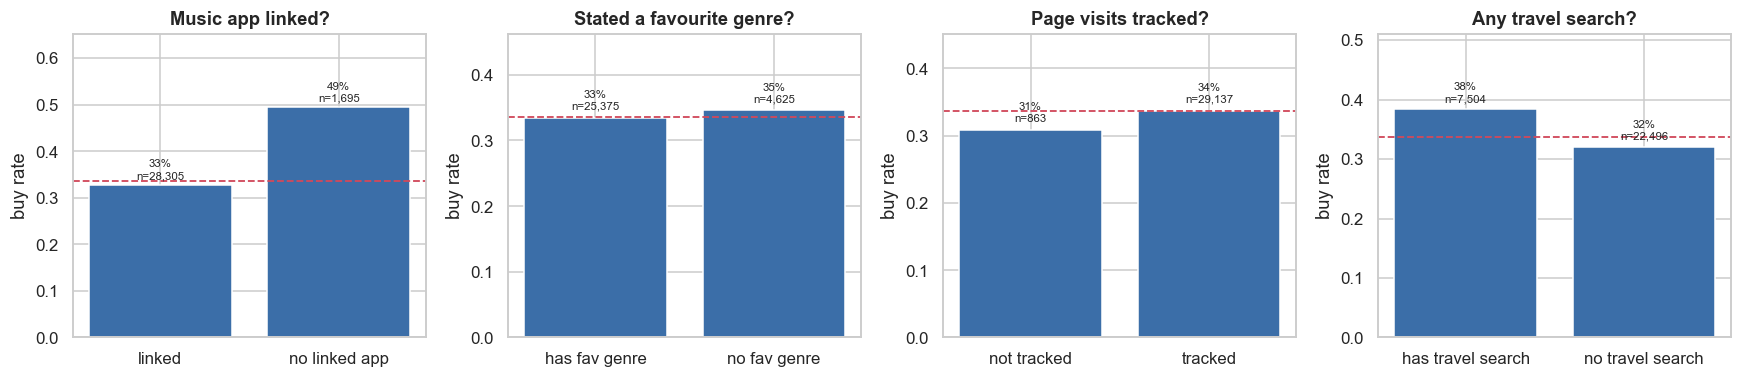

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
tmp = train.assign(
    app=np.where(train["music_app_user_id"].isna(), "no linked app", "linked"),
    fav=np.where(train["stated_favourite_genre"].isna(), "no fav genre", "has fav genre"),
    visits=np.where(train["event_page_visits_7d"].isna(), "not tracked", "tracked"),
    travel=np.where(train["travel_search_city"].isna(), "no travel search", "has travel search"),
)
for ax, c, t in zip(axes, ["app", "fav", "visits", "travel"],
                    ["Music app linked?", "Stated a favourite genre?", "Page visits tracked?", "Any travel search?"]):
    rate_plot(tmp, c, ax=ax, title=t, xlabel="")
plt.tight_layout(); plt.show()

> **What I take from this**
> - **`typical_ticket_spend` / `usual_booking_lead_days` blank = first-timer, 100% of the time.** That's not data loss, it's by design: you can't have a "usual spend" if you never bought. So the information is already in `first_timer`, and we shouldn't fill these with the median and pretend it's a normal user.
> - **No linked music app → ~49% buy rate** vs ~33% overall. Being unlinked is clearly *not* "this person doesn't care about music". In section 10 we'll see the JSON has two more "no data" cases (`empty` and `missing`) with the same pattern.
> - `event_page_visits_7d` blank = "tracking missing" (official definition), and it's only 3% of rows. Its buy rate is close to average.
> - The travel columns are blank 75% of the time and always together. A blank there simply means "no search recorded", which is a meaningful 0. We'll dig into it in section 9.
> - `stated_favourite_genre` blank → slightly *higher* buy rate, which I didn't expect. Small effect though.
>
> **→ Feature ideas / decisions**
> - Keep blanks as `NaN` for tree models (LightGBM/XGBoost/HistGB learn which way missing values should go at each split).
> - For linear models / kNN: impute **and** add a missing-indicator column, otherwise the "missing means something" info is lost.
> - Explicit flags: `has_app`, `visits_missing`, `has_fav_genre`, `has_travel_search`. Plus `first_timer` already exists.

---
## 6. Who are the users? (profile)

Now the user columns, one by one. Reminder of how to read the plots: blue bars = buy rate per group, red line = overall 33.6%, grey bar = blank values.

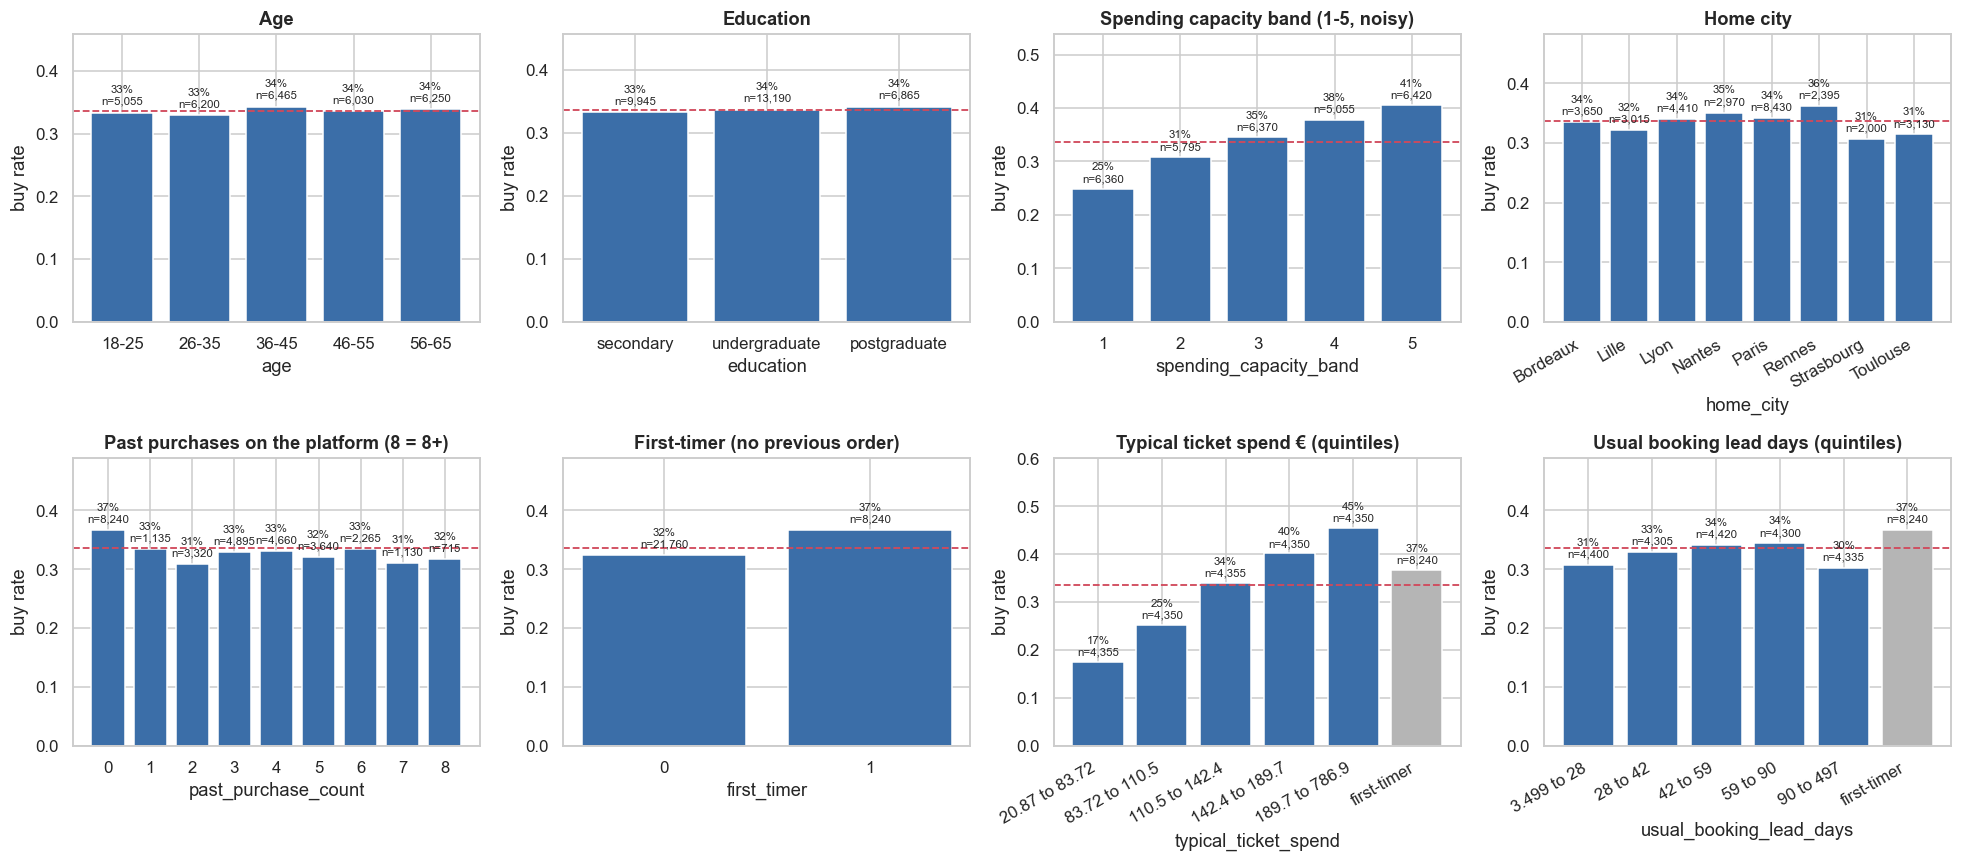

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()
rate_plot(train, "age", bins=[17, 25, 35, 45, 55, 65], labels=["18-25", "26-35", "36-45", "46-55", "56-65"], ax=axes[0], title="Age")
rate_plot(train, "education", ax=axes[1], title="Education", order=["secondary", "undergraduate", "postgraduate"])
rate_plot(train, "spending_capacity_band", ax=axes[2], title="Spending capacity band (1-5, noisy)")
rate_plot(train, "home_city", ax=axes[3], title="Home city", rot=30)
rate_plot(train.assign(x=train["past_purchase_count"].clip(upper=8)), "x", ax=axes[4],
          title="Past purchases on the platform (8 = 8+)", xlabel="past_purchase_count")
rate_plot(train, "first_timer", ax=axes[5], title="First-timer (no previous order)")
rate_plot(train, "typical_ticket_spend", q=5, ax=axes[6], title="Typical ticket spend € (quintiles)", rot=30, blank_label="first-timer")
rate_plot(train, "usual_booking_lead_days", q=5, ax=axes[7], title="Usual booking lead days (quintiles)", rot=30, blank_label="first-timer")
plt.tight_layout(); plt.show()

Mostly flat bars. A few comments:

- **Age, education, home city, past purchase count**: basically nothing on their own. The description even says there's no intended rule linking education or socio-economic category to artists, so I'm not surprised.
- **Spending capacity band**: the only clear trend. Goes from ~25% (band 1) to ~40% (band 5), steadily. Richer users buy more, makes sense. It's described as *noisy*, so let's see how it relates to what people actually spend:
- **First-timers buy slightly more** (37% vs 33%). Interesting. The description notes "first-timer" only means first time *on this platform*, not first concert ever.
- **`typical_ticket_spend` is actually strong**: 17% in the lowest quintile → 45% in the highest. People who usually spend a lot buy more. My guess is it's mostly the same story as the spending band (richer users), plus the fact that our tickets look *cheap* to someone who usually pays €200. Section 7 tests exactly that. The grey bar is the first-timers (37%).
- `usual_booking_lead_days` alone is meh (30-34%). In section 7 it becomes useful once we compare it to how far away each concert is.

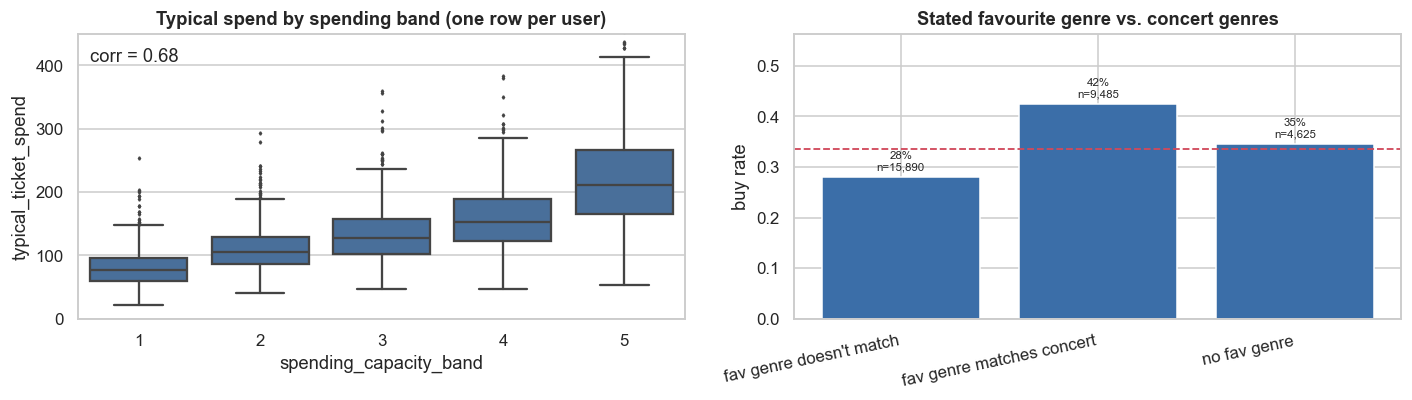

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
sns.boxplot(data=train.drop_duplicates("user_id"), x="spending_capacity_band", y="typical_ticket_spend",
            color=BLUE, fliersize=1.5, ax=axes[0])
axes[0].set_title("Typical spend by spending band (one row per user)")
axes[0].set_ylim(0, 450)
corr = train[["spending_capacity_band", "typical_ticket_spend"]].corr().iloc[0, 1]
axes[0].text(0.02, 0.95, f"corr = {corr:.2f}", transform=axes[0].transAxes, va="top")

train["fav_genre_in_concert"] = [
    ("no fav genre" if pd.isna(f) else ("fav genre matches concert" if f in g.split("|") else "fav genre doesn't match"))
    for f, g in zip(train["stated_favourite_genre"], train["genres"])]
rate_plot(train, "fav_genre_in_concert", ax=axes[1], title="Stated favourite genre vs. concert genres", xlabel="",
          order=["fav genre doesn't match", "fav genre matches concert", "no fav genre"], rot=12)
plt.tight_layout(); plt.show()

> **What I take from this**
> - The spending band is correlated with real spend (~0.68), so it's noisy but meaningful. It's the only "money" information we have for first-timers, who have no `typical_ticket_spend`.
> - The stated favourite genre on its own is useless, but **"does my favourite genre appear in this concert's genres?"** jumps from ~28% to ~42%. That's the pattern of this whole dataset: **most raw user columns are weak (money being the exception), user × concert matches are strong.** We'll see a much stronger version of this with the actual listening history in section 10.
>
> **→ Feature ideas**
> - `spending_capacity_band` as is (ordinal), `typical_ticket_spend` as is (NaN for first-timers)
> - `fav_genre_match` = stated favourite genre ∈ concert genres (0/1, NaN if no fav genre)
> - probably drop or keep-but-ignore: `education`, `age`, `home_city` (let the model / feature selection decide, but don't expect much)

---
## 7. The offer: price and timing

Each user gets each concert at one of **three price tiers**, with its own booking fee and discount. The official total cost is:

$$\text{total cost} = \text{ticket price} \times (1 - \text{discount}/100) + \text{booking fee}$$

In [15]:
tiers = (train.groupby(["concert_label", "ticket_price"])
         .agg(n=("buy", "size"), buy_rate=("buy", "mean"), booking_fee=("booking_fee", "mean"))
         .reset_index())
display(tiers)
print("discount distribution:", train["discount_pct"].value_counts(normalize=True).sort_index().round(3).to_dict())

for df in (train, test):
    df["total_cost"] = df["ticket_price"] * (1 - df["discount_pct"] / 100) + df["booking_fee"]
    df["price_vs_usual"] = df["total_cost"] / df["typical_ticket_spend"]   # NaN for first-timers

,concert_label,ticket_price,n,buy_rate,booking_fee
0,C01 Kendrick Lamar,84.000,1511,0.380,10.040
1,C01 Kendrick Lamar,105.000,3309,0.324,11.300
2,C01 Kendrick Lamar,131.250,1180,0.279,12.880
3,C02 Olivia Rodrigo,68.000,1491,0.343,9.080
4,C02 Olivia Rodrigo,85.000,3266,0.320,10.100
5,C02 Olivia Rodrigo,106.250,1243,0.277,11.380
6,C03 Taylor Swift,112.000,1509,0.473,11.720
7,C03 Taylor Swift,140.000,3313,0.374,13.400
8,C03 Taylor Swift,175.000,1178,0.318,15.500
9,C04 Tame Impala,60.000,1521,0.314,8.600


discount distribution: {0: 0.649, 10: 0.249, 20: 0.102}


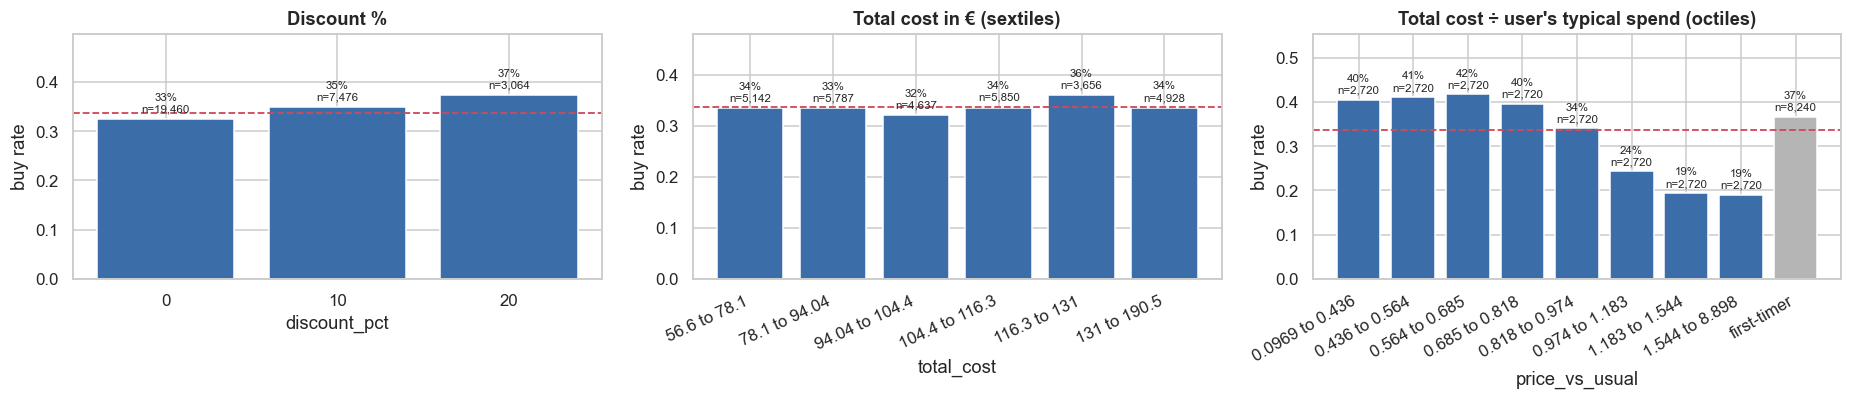

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
rate_plot(train, "discount_pct", ax=axes[0], title="Discount %")
rate_plot(train, "total_cost", q=6, ax=axes[1], title="Total cost in € (sextiles)", rot=25)
rate_plot(train, "price_vs_usual", q=8, ax=axes[2], keep_missing=True, blank_label="first-timer",
          title="Total cost ÷ user's typical spend (octiles)", rot=30)
plt.tight_layout(); plt.show()

This is my favourite plot of the section.

- The **absolute price barely matters** (middle plot). A €140 ticket isn't less attractive than a €68 one *in general*.
- But **price relative to what this person usually pays** (right plot) is very clear: as long as the ticket costs less than ~80% of their usual spend, the buy rate sits flat around 40-42%. Between ~80% and ~97% it starts to drop (34%), and once it's above their usual spend it **falls to ~19-24%**. It looks like a "this is more than I normally pay" threshold, not a smooth slope.
- Discounts help a little (32% → 37%).
- The grey bar on the right is the first-timers (no usual spend), and they buy at 37%.

But wait. In section 6 `typical_ticket_spend` alone was already strong (17% → 45%). Since the ratio has typical spend in the denominator, maybe the ratio is just "rich people buy more" in disguise? To check, I look at the ratio **inside** groups of users who spend about the same:

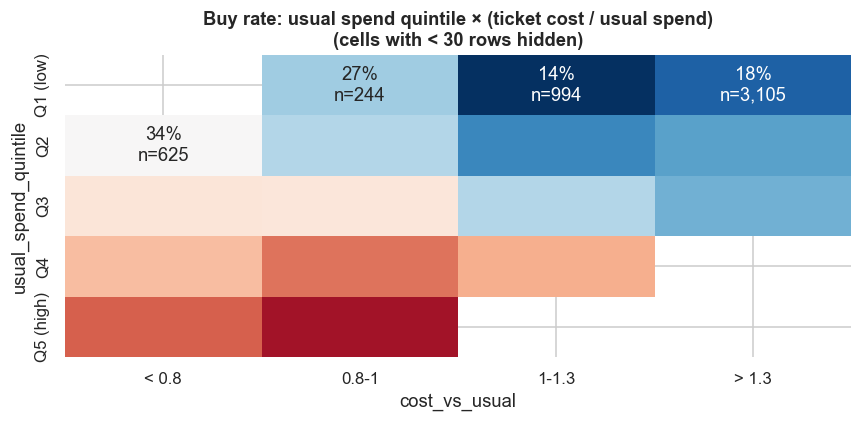

In [17]:
t = train[train["typical_ticket_spend"].notna()].copy()
t["usual_spend_quintile"] = pd.qcut(t["typical_ticket_spend"], 5, labels=["Q1 (low)", "Q2", "Q3", "Q4", "Q5 (high)"])
t["cost_vs_usual"] = pd.cut(t["price_vs_usual"], [0, 0.8, 1.0, 1.3, 10], labels=["< 0.8", "0.8-1", "1-1.3", "> 1.3"])
rate = t.pivot_table(index="usual_spend_quintile", columns="cost_vs_usual", values="buy", aggfunc="mean", observed=True)
size = t.pivot_table(index="usual_spend_quintile", columns="cost_vs_usual", values="buy", aggfunc="size", observed=True)
annot = rate.map(lambda v: "" if pd.isna(v) else f"{v:.0%}") + size.map(lambda v: "" if pd.isna(v) else f"\nn={int(v):,}")

fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(rate.where(size >= 30), annot=annot.where(size >= 30, ""), fmt="", cmap="RdBu_r", center=OVERALL, cbar=False, ax=ax)
ax.set_title("Buy rate: usual spend quintile × (ticket cost / usual spend)\n(cells with < 30 rows hidden)")
plt.tight_layout(); plt.show()

Both effects are real and they stack:

- **Down each column**, people who usually spend more buy more (the "rich users" effect).
- **Along each row**, i.e. among people with a similar budget, the buy rate still drops once the ticket costs more than they usually pay: Q1 goes 27% → 14-18%, Q2 34% → 21-23%, Q3 36% → 24-28%. Q4 stays flat (40-44%), but almost nobody in Q4 gets a ticket above their usual spend, so there isn't much to see there.

So the ratio isn't just typical spend in disguise. We keep both features. Also notice the empty corners: low spenders almost never get a "cheap" ticket and high spenders almost never get an "expensive" one, so the two features are tangled. Trees deal with that fine; for logistic regression it's a reason to keep an eye on the coefficients.

### Timing: is now "my moment" to book?

Each user has a `usual_booking_lead_days`: how many days before a concert they normally buy. At the snapshot, each concert is a fixed number of days away (24, 40, 56, 72, 88). If the concert is roughly at the distance where this person normally books, then **this week** should be their moment.

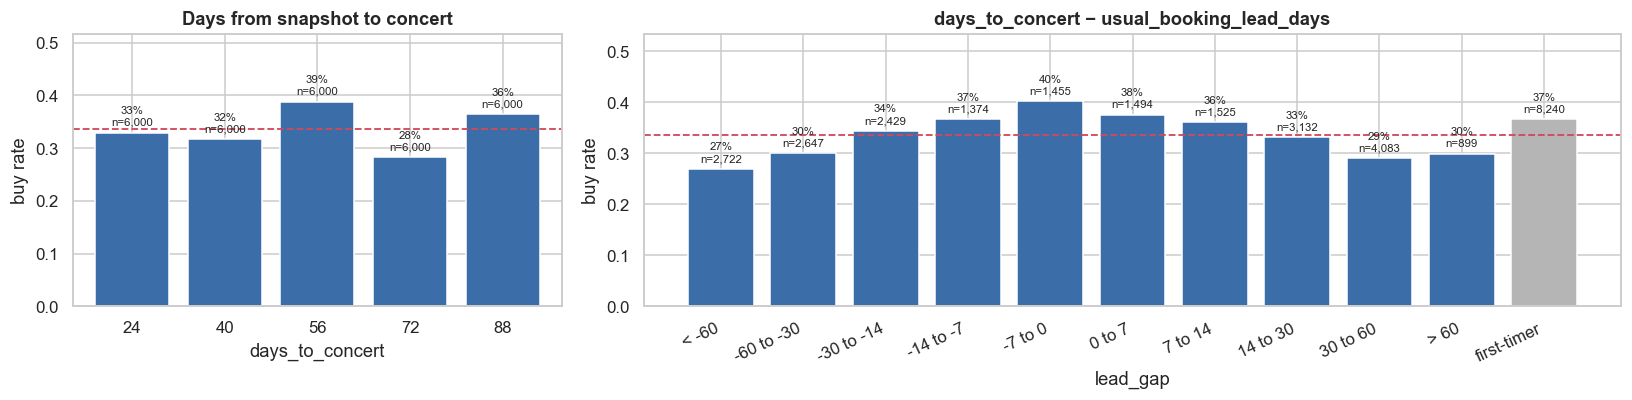

In [18]:
for df in (train, test):
    df["days_to_concert"] = (pd.to_datetime(df["concert_at"]) - pd.to_datetime(df["prediction_at"])).dt.days
    df["lead_gap"] = df["days_to_concert"] - df["usual_booking_lead_days"]   # >0: concert is further than usual

fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1, 2]})
rate_plot(train, "days_to_concert", ax=axes[0], title="Days from snapshot to concert")
rate_plot(train, "lead_gap", bins=[-500, -60, -30, -14, -7, 0, 7, 14, 30, 60, 500], keep_missing=True, ax=axes[1],
          labels=["< -60", "-60 to -30", "-30 to -14", "-14 to -7", "-7 to 0", "0 to 7", "7 to 14", "14 to 30", "30 to 60", "> 60"],
          blank_label="first-timer",
          title="days_to_concert − usual_booking_lead_days", rot=25)
plt.tight_layout(); plt.show()

> **What I take from this**
> - The lead gap gives a nice **hump**: when the gap is close to 0 (concert about as far away as this person usually books), the buy rate is ~38-40%. When the concert is way too far (gap > 30 days) or way too close compared to their habit (gap < −30), it drops to ~27-30%.
> - Important for modelling: this relationship is **not monotonic**. A linear model given the raw `lead_gap` can't capture a hump, so we should also give it `abs(lead_gap)`. Trees can handle it either way.
> - Same logic for price: the ratio is what matters, not the price itself. **Relative features beat raw features** again.
>
> **→ Feature ideas**
> - `total_cost` (official formula), `discount_pct`
> - `price_vs_usual` = total_cost / typical_ticket_spend, maybe also a flag `price_above_usual` = ratio > 1
> - `abs_lead_gap` = |days_to_concert − usual_booking_lead_days| (NaN for first-timers)
> - for first-timers: `total_cost` vs `spending_capacity_band` could act as a weaker substitute

---
## 8. Geography: how far is the concert?

Users live in 8 cities, concerts are in 5. My intuition: going to a concert in your own city is a much easier decision than one that needs a train ticket and a hotel.

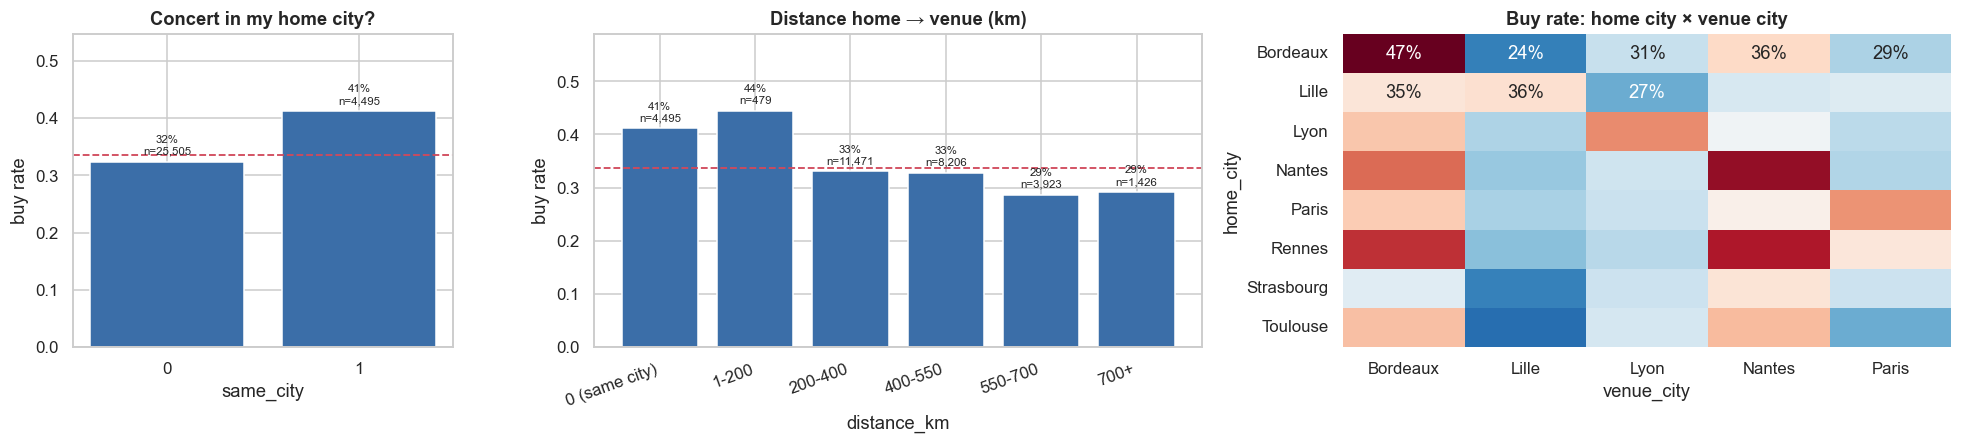

In [19]:
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

for df in (train, test):
    df["distance_km"] = haversine_km(df["home_lat"], df["home_lon"], df["venue_lat"], df["venue_lon"])
    df["same_city"] = (df["home_city"] == df["venue_city"]).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.2), gridspec_kw={"width_ratios": [1, 1.6, 1.6]})
rate_plot(train, "same_city", ax=axes[0], title="Concert in my home city?")
rate_plot(train, "distance_km", bins=[-1, 1, 200, 400, 550, 700, 1000],
          labels=["0 (same city)", "1-200", "200-400", "400-550", "550-700", "700+"], ax=axes[1],
          title="Distance home → venue (km)", rot=20)
pv = train.pivot_table(index="home_city", columns="venue_city", values="buy")
sns.heatmap(pv, annot=True, fmt=".0%", cmap="RdBu_r", center=OVERALL, cbar=False, ax=axes[2])
axes[2].set_title("Buy rate: home city × venue city")
plt.tight_layout(); plt.show()

> **What I take from this**
> - Same city: ~41% vs ~32%. You can see it on the diagonal of the heatmap (Bordeaux→Bordeaux 47%, Nantes→Nantes 45%, Paris→Paris 40%, Lyon→Lyon 40%).
> - Distance: under 200 km is as good as same city (44%, but only 479 rows, basically Rennes ↔ Nantes, ~100 km). From 200 km on it's ~33%, and above 550 km ~29%. So it's more "local vs not" than a smooth slope.
> - The heatmap also shows some cities are "close enough": Rennes users like Nantes (44%) and Bordeaux (43%). Lille as a venue is low for everyone, but that's mixed up with it being the Tame Impala concert (lowest overall rate), so I wouldn't read too much into it.
>
> **→ Feature ideas**
> - `same_city` (0/1), `distance_km`
> - maybe distance buckets for linear models (local / regional / far)

---
## 9. Engagement: page visits, wishlist, travel searches

These are the "recent behaviour" signals: what the user did around this specific concert during the week before the snapshot.

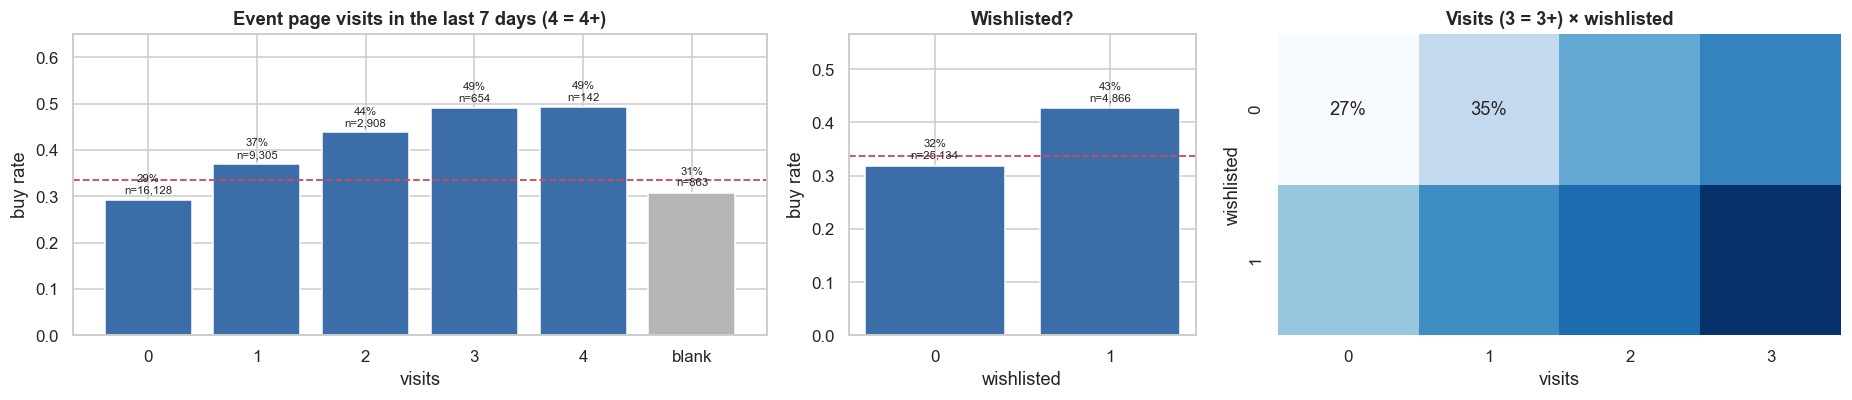

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8), gridspec_kw={"width_ratios": [1.6, 0.8, 1.3]})
rate_plot(train.assign(v=train["event_page_visits_7d"].clip(upper=4).astype("Int64")), "v", ax=axes[0],
          title="Event page visits in the last 7 days (4 = 4+)", xlabel="visits")
rate_plot(train, "wishlisted", ax=axes[1], title="Wishlisted?")
pv = train.assign(v=train["event_page_visits_7d"].clip(upper=3).astype("Int64")).pivot_table(
    index="wishlisted", columns="v", values="buy")
sns.heatmap(pv, annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=axes[2])
axes[2].set_title("Visits (3 = 3+) × wishlisted"); axes[2].set_xlabel("visits")
plt.tight_layout(); plt.show()

Both work in the expected direction, and they add up: 0 visits and not wishlisted is the weakest cell, many visits and wishlisted the strongest. Nothing surprising, but solid.

### Travel searches, the interesting one

A row can have a pre-snapshot travel/accommodation search: a city and a planned arrival date. First question: is this a user-level thing (same search copied on all 5 rows of the user) or is it attached to specific rows?

In [21]:
for df in (train, test):
    arrival = pd.to_datetime(df["travel_search_arrival"])
    concert_day = pd.to_datetime(df["concert_at"]).dt.tz_localize(None).dt.normalize()
    df["travel_to_venue"] = (df["travel_search_city"] == df["venue_city"]).astype(int)
    df["arrival_gap_days"] = (concert_day - arrival).dt.days     # >0: arrive before the concert day

print("share of rows with a travel search:", train["travel_search_city"].notna().mean().round(3))
print("is the search city the same on all 5 rows of a user?",
      train.groupby("user_id")["travel_search_city"].nunique(dropna=False).eq(1).mean().round(3))
print("search cities:", train["travel_search_city"].value_counts().to_dict())

share of rows with a travel search: 0.25
is the search city the same on all 5 rows of a user? 0.229
search cities: {'Lyon': 1268, 'Lille': 1237, 'Paris': 1193, 'Bordeaux': 1190, 'Nantes': 1179, 'Rennes': 493, 'Strasbourg': 476, 'Toulouse': 468}


So it's **row-level**: the search city varies across a user's five rows, and a user can have several searches sitting on different concert rows. And it doesn't always point to a venue city (Rennes, Strasbourg and Toulouse show up too, and nobody plays there). So the question for each row is: does the search **match this row's venue**, and does the date line up with the concert?

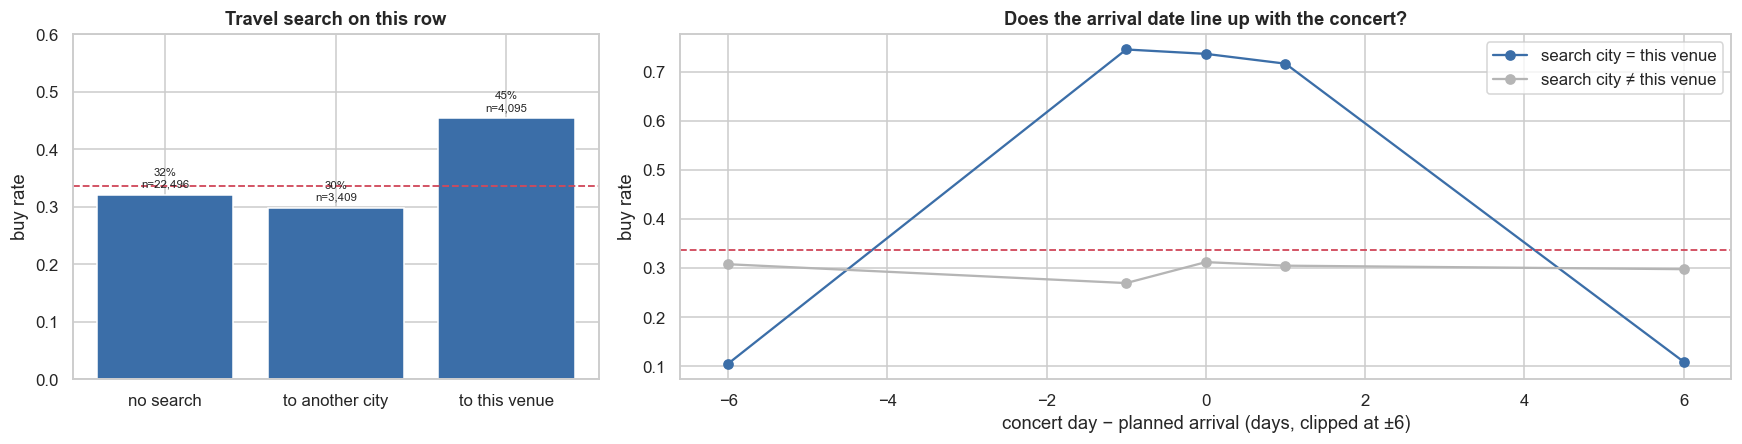

                                     n  rate
case                     date_ok            
search city = this venue False    1827 0.107
                         True     2268 0.733
search city ≠ this venue False    1546 0.303
                         True     1863 0.295


In [22]:
has = train[train["travel_search_city"].notna()].copy()
has["case"] = np.where(has["travel_to_venue"] == 1, "search city = this venue", "search city ≠ this venue")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.2), gridspec_kw={"width_ratios": [1, 2]})
rate_plot(train.assign(c=np.where(train["travel_search_city"].isna(), "no search",
                       np.where(train["travel_to_venue"] == 1, "to this venue", "to another city"))),
          "c", ax=axes[0], title="Travel search on this row", xlabel="",
          order=["no search", "to another city", "to this venue"])
g = (has.assign(gap=has["arrival_gap_days"].clip(-6, 6))
     .groupby(["case", "gap"])["buy"].mean().unstack(0))
for col, color in zip(g.columns, [BLUE, GREY]):
    axes[1].plot(g.index, g[col], marker="o", label=col, color=color if col.startswith("search city =") else GREY)
axes[1].axhline(OVERALL, ls="--", color=RED, lw=1.2)
axes[1].set_xlabel("concert day − planned arrival (days, clipped at ±6)")
axes[1].set_ylabel("buy rate"); axes[1].legend()
axes[1].set_title("Does the arrival date line up with the concert?")
plt.tight_layout(); plt.show()

print(rate_table(has.assign(date_ok=has["arrival_gap_days"].abs() <= 1), ["case", "date_ok"]))

This is the cleanest signal in the whole CSV.

- Searching travel to **this concert's city with an arrival within ±1 day of the concert**: ~**74%** buy.
- Searching to this city but with the arrival date **off by several days**: ~**10%**. That's way *below* average. My reading: this person is going to that city for something else (work, family...) and it's actually a sign they're *not* planning the concert.
- A search to **another** city: ~30%, a bit below average. It just doesn't concern this concert.

> **What I take from this**
> - "Has a travel search" alone is a mediocre feature. **City and date together** make it a near-rule.
> - This is a nice example for the report: the raw columns `travel_search_city` and `travel_search_arrival` are almost useless to a model, but one engineered boolean gets you 74% vs 10%.
>
> **→ Feature ideas**
> - `travel_match` = (search city == venue city) AND (|arrival gap| ≤ 1)
> - `travel_wrong_date` = (search city == venue city) AND (|arrival gap| > 1)
> - `arrival_gap_days` kept as numeric for trees
> - `event_page_visits_7d`, `wishlisted`, `visits_missing` flag

---
## 10. The music app JSON (the big one)

The competition page says: *"Turning [the listening history] into useful user–artist features [...] is where most of the signal is."* So this section is the longest.

### 10.1 What's inside

The JSON is nested 3 levels deep. A quick look at the top level and one account:

In [23]:
with open(DATA_DIR / "music_app.json") as f:
    app = json.load(f)

print("top-level keys:", list(app.keys()))
print("history_ends_before:", app["history_ends_before"])
print("number of accounts:", len(app["accounts"]))

catalog = pd.DataFrame(app["catalog"]["artists"])
catalog["genres"] = catalog["genres"].str.join("|")
catalog["is_concert_artist"] = catalog["artist_id"].isin(train["artist_id"].unique())
display(catalog)

acc0 = app["accounts"][0]
print("one account ->", {k: (v if k != "sessions" else f"[{len(v)} sessions]") for k, v in acc0.items()})
print("one session ->", json.dumps(acc0["sessions"][0], indent=1)[:600])

top-level keys: ['schema_version', 'history_ends_before', 'catalog', 'accounts']
history_ends_before: 2026-10-01T00:00:00Z
number of accounts: 9432


,artist_id,artist_name,genres,is_concert_artist
0,A01,Kendrick Lamar,hip_hop|rnb_soul|jazz_funk|pop,True
1,A02,Olivia Rodrigo,pop|pop_rock|alternative,True
2,A03,Taylor Swift,pop|pop_rock|alternative|folk_country,True
3,A04,Tame Impala,pop|alternative|electronic|psychedelic,True
4,A05,SZA,hip_hop|rnb_soul|jazz_funk|pop|alternative,True
5,A06,Library hip hop,hip_hop,False
6,A07,Library rnb soul,rnb_soul,False
7,A08,Library jazz funk,jazz_funk,False
8,A09,Library pop,pop,False
9,A10,Library pop rock,pop_rock,False


one account -> {'music_app_user_id': 'M1213C172', 'activity_status': 'active', 'sessions': '[53 sessions]'}
one session -> {
 "session_id": "S001",
 "tracks": [
  {
   "played_at": "2026-09-30T21:22:16Z",
   "artist_id": "A11",
   "genre": "alternative",
   "track_id": "A11_6",
   "played_ms": 132490,
   "track_ms": 160000,
   "source": "autoplay",
   "saved": false
  }
 ]
}


So the structure is:

```
accounts (one per music_app_user_id)
 ├── activity_status: active / empty / missing
 └── sessions (one session = one listening day)
      └── tracks (one row per play)
           played_at, artist_id, genre, track_id, played_ms, track_ms, source (search/autoplay), saved
```

The 16 "artists" are the 5 concert artists (A01-A05) plus 11 fictional **"Library ..." acts**, one per genre. Those library acts are basically there to tell us the user's genre taste.

### 10.2 Flatten it into a table

Models want tables, so step one is to "flatten" the JSON: one row per track play. This is the same thing as `UNNEST` in SQL.

In [24]:
accounts = pd.DataFrame([{"music_app_user_id": a["music_app_user_id"], "status": a["activity_status"],
                          "n_sessions": len(a["sessions"])} for a in app["accounts"]])

plays = pd.DataFrame([
    {"music_app_user_id": a["music_app_user_id"], "session_id": s["session_id"], **t}
    for a in app["accounts"] for s in a["sessions"] for t in s["tracks"]
])
plays["played_at"] = pd.to_datetime(plays["played_at"])
plays["days_ago"] = (SNAPSHOT - plays["played_at"]).dt.total_seconds() / 86400
plays["completion"] = plays["played_ms"] / plays["track_ms"]
plays["is_search"] = (plays["source"] == "search").astype(int)
plays["saved"] = plays["saved"].astype(int)
plays["is_concert_artist"] = plays["artist_id"].isin(catalog.loc[catalog["is_concert_artist"], "artist_id"])

del app  # free memory, we have everything we need in the two tables
print(f"{len(plays):,} track plays from {plays['music_app_user_id'].nunique():,} accounts")
print("time range:", plays["played_at"].min(), "->", plays["played_at"].max())
plays.head()

551,901 track plays from 8,746 accounts
time range: 2026-07-03 00:00:03+00:00 -> 2026-09-30 22:12:37+00:00


,music_app_user_id,session_id,played_at,artist_id,genre,track_id,played_ms,track_ms,source,saved,days_ago,completion,is_search,is_concert_artist
0,M1213C172,S001,2026-09-30 21:22:16+00:00,A11,alternative,A11_6,132490,160000,autoplay,0,0.110,0.828,0,False
1,M1213C172,S002,2026-09-29 00:22:53+00:00,A08,jazz_funk,A08_6,198000,198000,autoplay,0,1.984,1.000,0,False
2,M1213C172,S003,2026-09-28 00:42:34+00:00,A08,jazz_funk,A08_12,223698,273000,search,1,2.970,0.819,1,False
3,M1213C172,S003,2026-09-28 17:59:57+00:00,A11,alternative,A11_12,205737,232000,search,0,2.250,0.887,1,False
4,M1213C172,S004,2026-09-27 21:36:03+00:00,A16,metal,A16_10,180541,196000,search,0,3.100,0.921,1,False


### 10.3 Account status: the missing-data trap

Remember: a user can be in **four** situations, and the description is very explicit about them:

| situation | where you see it | meaning |
|---|---|---|
| no linked app | `music_app_user_id` blank in the CSV | no account at all |
| `empty` | status in JSON, 0 sessions | linked, but truly no listening in the window |
| `missing` | status in JSON, 0 sessions | **no coverage**, an empty export here does *not* mean no listening |
| `active` | status in JSON, sessions present | normal case |

           count   mean    min    max
status                               
active  8746.000 44.323 23.000 69.000
empty    379.000  0.000  0.000  0.000
missing  307.000  0.000  0.000  0.000


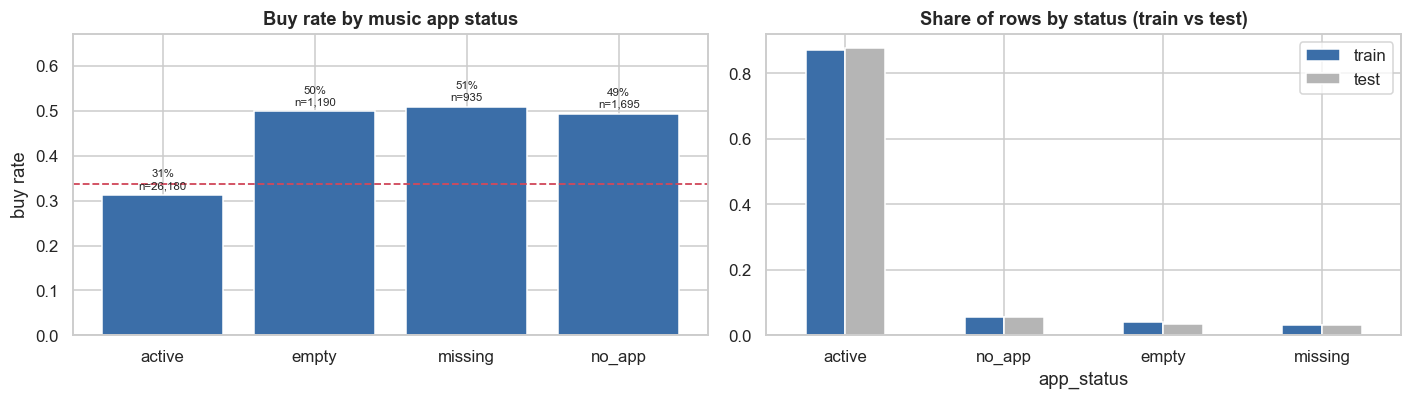

In [25]:
print(accounts.groupby("status")["n_sessions"].describe()[["count", "mean", "min", "max"]])

for df in (train, test):
    df["app_status"] = (df[["music_app_user_id"]]
                        .merge(accounts[["music_app_user_id", "status"]], on="music_app_user_id", how="left")["status"]
                        .fillna("no_app").values)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
rate_plot(train, "app_status", ax=axes[0], title="Buy rate by music app status", xlabel="",
          order=["active", "empty", "missing", "no_app"])
share = pd.DataFrame({"train": train["app_status"].value_counts(normalize=True),
                      "test": test["app_status"].value_counts(normalize=True)})
share.plot.bar(ax=axes[1], color=[BLUE, GREY], rot=0)
axes[1].set_title("Share of rows by status (train vs test)")
plt.tight_layout(); plt.show()

> **What I take from this**
> - `empty` and `missing` look **exactly the same** inside the JSON (0 sessions). The only way to tell them apart is the `activity_status` field. If we just count plays, both become "0 plays", which is wrong for `missing` (no data ≠ no interest).
> - All three "no data" groups buy at ~50%, way above the ~31% of active users. I'm not going to over-interpret why (this is a synthetic cohort), but the model needs to be **told** which group a user is in.
> - Practical rule for us: for `missing` and `no_app` users, listening features should be **NaN**, not 0. For `empty` users, 0 is honestly correct (they really didn't listen). And we add `app_status` as a categorical feature.
>
> **→ Feature ideas**
> - `app_status` ∈ {active, empty, missing, no_app}
> - listening features = NaN for missing / no_app, 0 for empty

### 10.4 What does the listening look like overall?

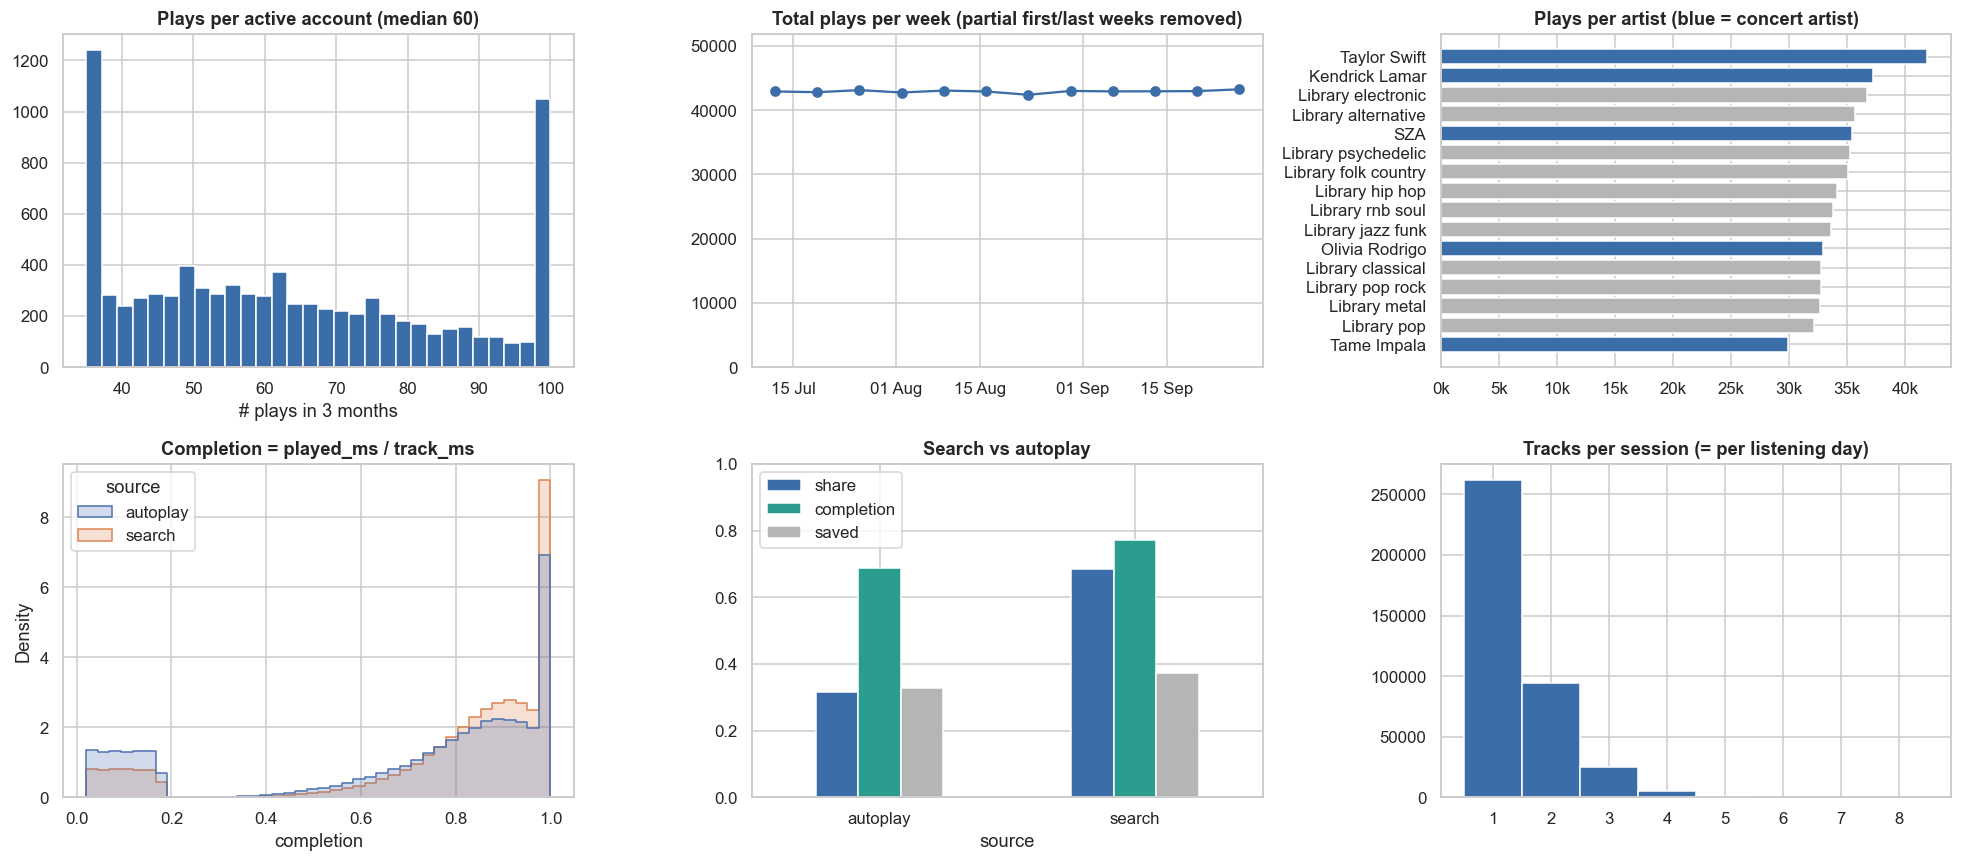

concert artists = 32.1% of all plays


In [26]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8))

per_acc = plays.groupby("music_app_user_id").size()
axes[0, 0].hist(per_acc, bins=30, color=BLUE)
axes[0, 0].set_title(f"Plays per active account (median {per_acc.median():.0f})"); axes[0, 0].set_xlabel("# plays in 3 months")

weekly = plays.set_index("played_at").resample("W")["artist_id"].size()
axes[0, 1].plot(weekly.index[1:-1], weekly.values[1:-1], marker="o", color=BLUE)
axes[0, 1].set_title("Total plays per week (partial first/last weeks removed)")
axes[0, 1].set_ylim(0, weekly.max() * 1.2)
axes[0, 1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

art = (plays.groupby("artist_id").size().rename("plays").reset_index()
       .merge(catalog[["artist_id", "artist_name", "is_concert_artist"]], on="artist_id")
       .sort_values("plays", ascending=True))
axes[0, 2].barh(art["artist_name"], art["plays"], color=[BLUE if c else GREY for c in art["is_concert_artist"]])
axes[0, 2].set_title("Plays per artist (blue = concert artist)")
axes[0, 2].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x / 1000:.0f}k"))

sns.histplot(data=plays, x="completion", hue="source", bins=40, stat="density", common_norm=False,
             element="step", ax=axes[1, 0])
axes[1, 0].set_title("Completion = played_ms / track_ms")

src = plays.groupby("source").agg(share=("source", "size"), completion=("completion", "mean"), saved=("saved", "mean"))
src["share"] = src["share"] / src["share"].sum()
src.plot.bar(ax=axes[1, 1], rot=0, color=[BLUE, GREEN, GREY])
axes[1, 1].set_title("Search vs autoplay"); axes[1, 1].set_ylim(0, 1)

sess = plays.groupby(["music_app_user_id", "session_id"]).size()
axes[1, 2].hist(sess, bins=np.arange(0.5, sess.max() + 1.5), color=BLUE)
axes[1, 2].set_title("Tracks per session (= per listening day)")
plt.tight_layout(); plt.show()

print(f"concert artists = {plays['is_concert_artist'].mean():.1%} of all plays")

> **What I take from this**
> - **Plays per account are squeezed between 35 and 100**, with big piles exactly at 35 and at 100. That looks like the histories were sampled and capped (the description says they're "synthetic samples of activity, not a complete lifetime record"). So a heavy listener and an extreme listener can both show 100 plays. Consequence: **shares and ranks within the user are more trustworthy than raw counts** across users.
> - Volume is flat over time: no global "hype" building up before the presale. So if a user's listening to an artist rises recently, that's personal, not a dataset-wide trend.
> - The 5 concert artists make up ~32% of plays, the rest is the genre library.
> - Two types of listening: **search** (deliberate, ~2/3 of plays) vs **autoplay** (passive). Searched plays get finished more (77% vs 69% completion) and saved slightly more. The description calls this "deliberate versus passive listening", basically a hint.
> - Completion has a separate bump near 0: ~15% of plays stop before 20% of the track, then there's literally nothing between 0.2 and 0.3. So "skip" is a clean category here (I use completion < 0.3). A skip is the opposite of a fan signal.

### 10.5 User × artist affinity: does listening to the artist predict buying?

This is the core idea. For each user and each **concert artist**, I compute a few numbers from the plays, then join them onto the train rows (user × concert → user × artist).

What I compute and why:

| feature | intuition |
|---|---|
| `art_plays` | how much they listen to this artist at all |
| `art_search` | deliberate plays: they went looking for this artist |
| `art_saved` | saving a track is a strong "I like this" |
| `art_completion` | do they finish the songs or skip? |
| `art_distinct_tracks` | fans explore the catalogue, casuals replay one hit |
| `art_share` | artist plays / all plays: how much of *their* listening this artist takes |
| `art_days_since_last` | recency: did they listen this week or 2 months ago? |
| `art_plays_14d` | short-term heat |

In [27]:
cp = plays[plays["is_concert_artist"]].copy()
cp["in_14d"] = (cp["days_ago"] <= 14).astype(int)
cp["skip"] = (cp["completion"] < 0.3).astype(int)

ua = cp.groupby(["music_app_user_id", "artist_id"]).agg(
    art_plays=("artist_id", "size"),
    art_search=("is_search", "sum"),
    art_saved=("saved", "sum"),
    art_completion=("completion", "mean"),
    art_skips=("skip", "sum"),
    art_distinct_tracks=("track_id", "nunique"),
    art_days_since_last=("days_ago", "min"),
    art_plays_14d=("in_14d", "sum"),
).reset_index()
total = plays.groupby("music_app_user_id").size().rename("total_plays").reset_index()
ua = ua.merge(total, on="music_app_user_id")
ua["art_share"] = ua["art_plays"] / ua["total_plays"]


def add_artist_features(df):
    out = df.merge(ua.drop(columns="total_plays"), on=["music_app_user_id", "artist_id"], how="left")
    count_cols = ["art_plays", "art_search", "art_saved", "art_skips", "art_distinct_tracks", "art_plays_14d", "art_share"]
    has_data = out["app_status"].isin(["active", "empty"])
    # active/empty users who never played this artist -> a real 0. missing / no_app -> stays NaN
    out.loc[has_data, count_cols] = out.loc[has_data, count_cols].fillna(0)
    out["art_skip_rate"] = out["art_skips"] / out["art_plays"].replace(0, np.nan)   # only defined if played
    return out


train = add_artist_features(train)
test = add_artist_features(test)
act = train[train["app_status"] == "active"]   # for the plots below I only look at active users
print(f"active-user rows: {len(act):,} | rows where the user never played this artist: {(act['art_plays'] == 0).mean():.1%}")

active-user rows: 26,180 | rows where the user never played this artist: 20.3%


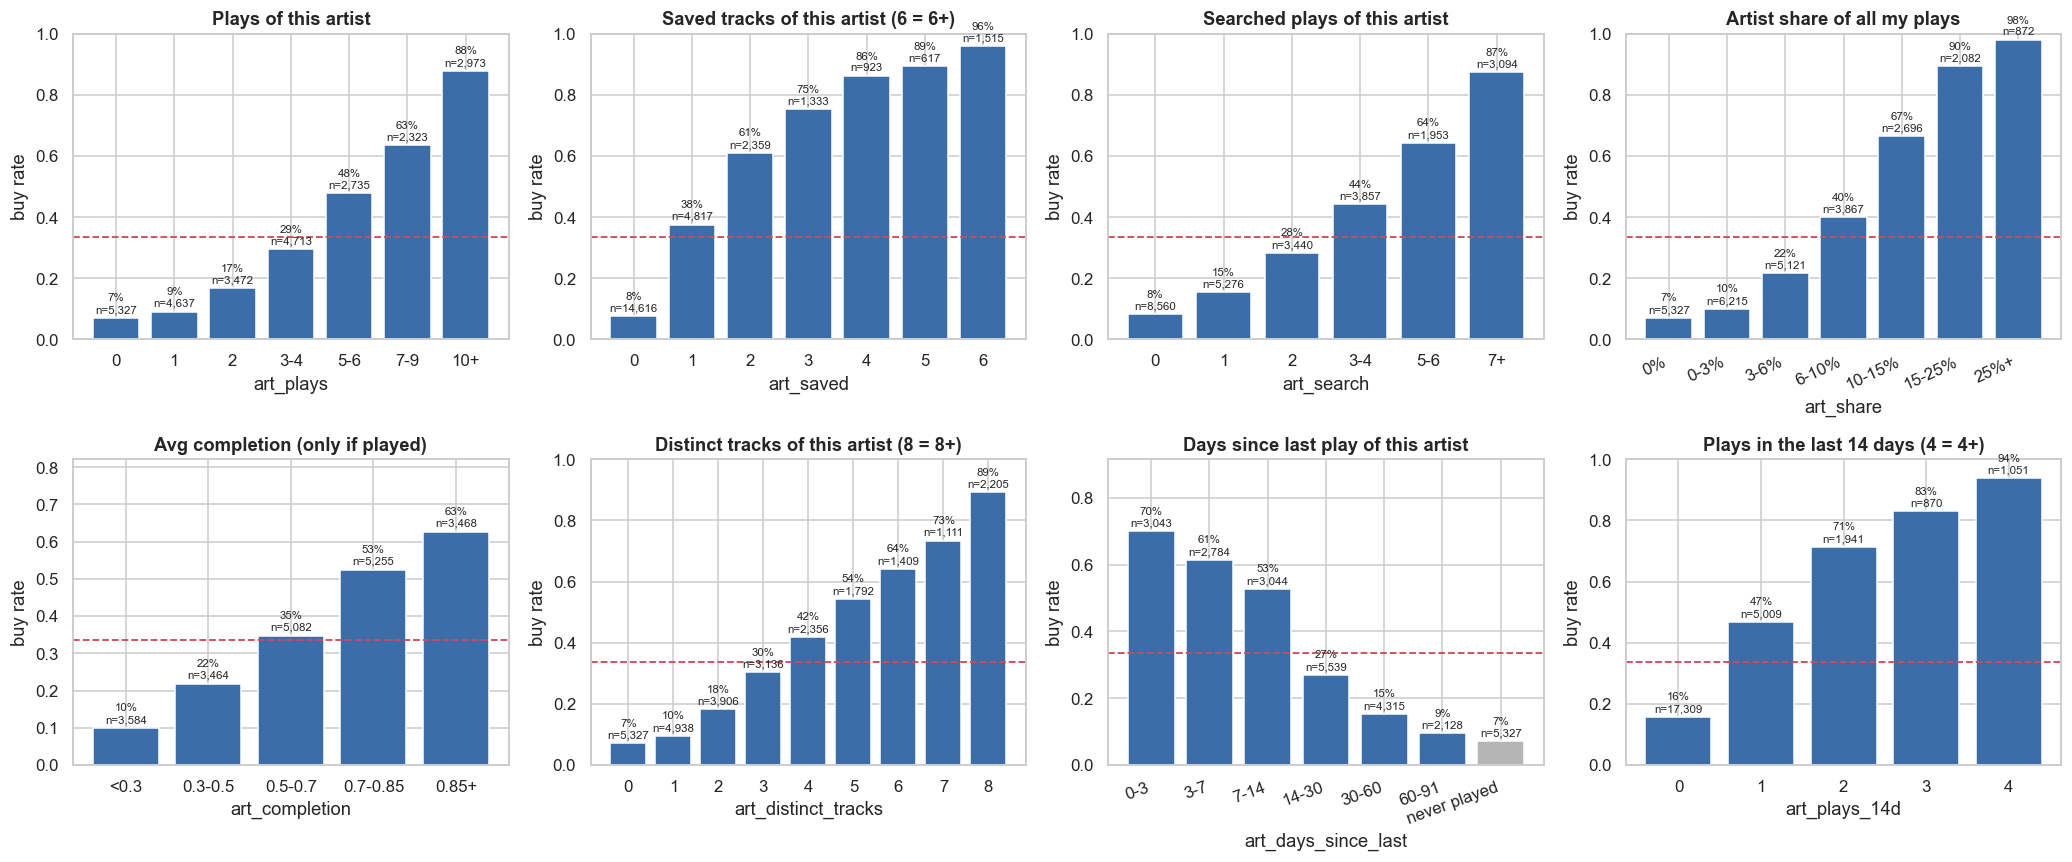

In [28]:
fig, axes = plt.subplots(2, 4, figsize=(19, 8))
axes = axes.ravel()
rate_plot(act, "art_plays", bins=[-1, 0, 1, 2, 4, 6, 9, 100], labels=["0", "1", "2", "3-4", "5-6", "7-9", "10+"],
          ax=axes[0], title="Plays of this artist")
rate_plot(act.assign(x=act["art_saved"].clip(upper=6).astype(int)), "x", ax=axes[1],
          title="Saved tracks of this artist (6 = 6+)", xlabel="art_saved")
rate_plot(act, "art_search", bins=[-1, 0, 1, 2, 4, 6, 100], labels=["0", "1", "2", "3-4", "5-6", "7+"], ax=axes[2],
          title="Searched plays of this artist")
rate_plot(act, "art_share", bins=[-0.001, 0, 0.03, 0.06, 0.1, 0.15, 0.25, 1],
          labels=["0%", "0-3%", "3-6%", "6-10%", "10-15%", "15-25%", "25%+"], ax=axes[3],
          title="Artist share of all my plays", rot=25)
rate_plot(act, "art_completion", bins=[0, 0.3, 0.5, 0.7, 0.85, 1.0], labels=["<0.3", "0.3-0.5", "0.5-0.7", "0.7-0.85", "0.85+"],
          keep_missing=False, ax=axes[4], title="Avg completion (only if played)")
rate_plot(act.assign(x=act["art_distinct_tracks"].clip(upper=8).astype(int)), "x", ax=axes[5],
          title="Distinct tracks of this artist (8 = 8+)", xlabel="art_distinct_tracks")
rate_plot(act, "art_days_since_last", bins=[0, 3, 7, 14, 30, 60, 91], labels=["0-3", "3-7", "7-14", "14-30", "30-60", "60-91"],
          ax=axes[6], title="Days since last play of this artist", blank_label="never played", rot=20)
rate_plot(act.assign(x=act["art_plays_14d"].clip(upper=4).astype(int)), "x", ax=axes[7],
          title="Plays in the last 14 days (4 = 4+)", xlabel="art_plays_14d")
plt.tight_layout(); plt.show()

Now **this** is signal. Compare these bars to the flat ones in section 6.

- **Never played the artist** (≈20% of active rows): buy rate **~6-7%**. Almost nobody buys a ticket for an artist they don't listen to. Makes total sense.
- Every measure climbs steadily: more plays, more saves, more searches, bigger share, more distinct tracks → higher buy rate, up to **85-95%** in the top bins. Saving is the cleanest: 0 saved tracks ≈ 8%, 1 ≈ 38%, 3 ≈ 76%, 6+ ≈ 96%.
- **Recency** is huge: last played in the past 3 days → ~70%, last played 2-3 months ago → under 10%. Not just "do I like them" but "are they on my mind right now".
- **Completion** works too: people whose average completion on this artist is below 0.3 buy ~10%, way below average, even though they did play the artist.

### 10.6 Is this the artist I like *most*?

Each user is offered all five concerts, so a natural question for a person is "which of these five do I care about most?" I rank the five concert artists within each user by number of plays (rank 1 = most played; ties get the same, best rank).

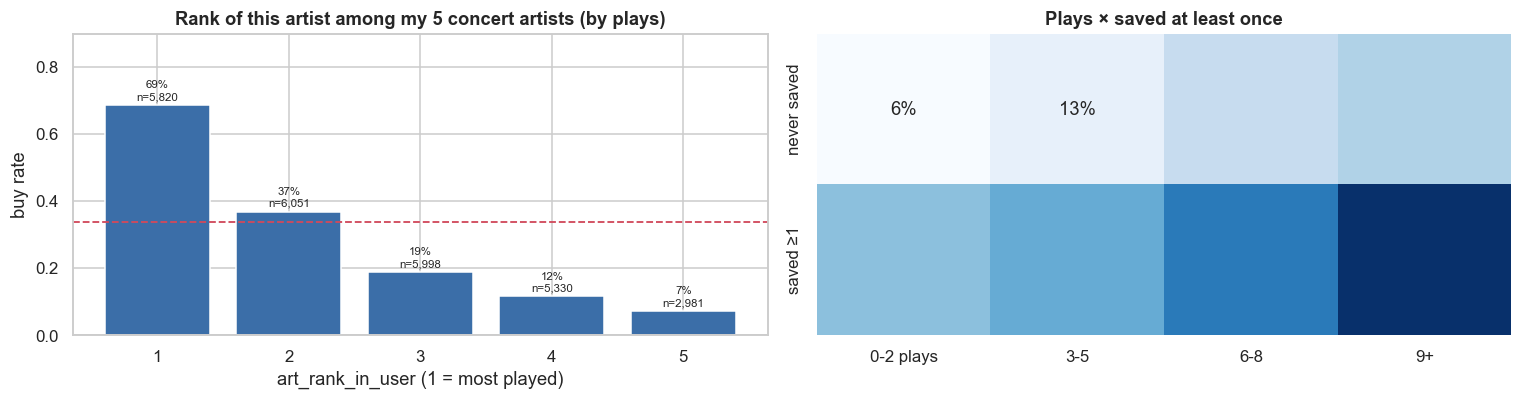

In [29]:
for df in (train, test):
    df["art_rank_in_user"] = df.groupby("user_id")["art_plays"].rank(ascending=False, method="min")
    df["art_plays_vs_user_max"] = df["art_plays"] / df.groupby("user_id")["art_plays"].transform("max").replace(0, np.nan)

act = train[train["app_status"] == "active"]
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
rate_plot(act.assign(x=act["art_rank_in_user"].astype(int)), "x", ax=axes[0],
          title="Rank of this artist among my 5 concert artists (by plays)", xlabel="art_rank_in_user (1 = most played)")

heat = (act.assign(plays=act["art_plays"].clip(upper=10) // 3 * 3, saved_any=(act["art_saved"] > 0).map({True: "saved ≥1", False: "never saved"}))
        .pivot_table(index="saved_any", columns="plays", values="buy"))
heat.columns = ["0-2 plays", "3-5", "6-8", "9+"]
sns.heatmap(heat, annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=axes[1])
axes[1].set_title("Plays × saved at least once"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

> **What I take from this**
> - Rank 1 → ~69% buy, rank 2 → ~37%, rank 5 → ~7%. Same raw play count can mean very different things depending on the person: 5 plays is a lot for someone who barely listens, nothing for a heavy user. **Comparing within the user** fixes that.
> - Saving and playing reinforce each other (right heatmap): lots of plays **and** saved at least once → ~85%.

### 10.7 Genre taste: from the library acts

The concert artists are connected to several genres (e.g. SZA: hip_hop | rnb_soul | jazz_funk | pop | alternative). The library acts tell us which genres a user listens to in general. So: what share of my total listening falls into this concert's genres?

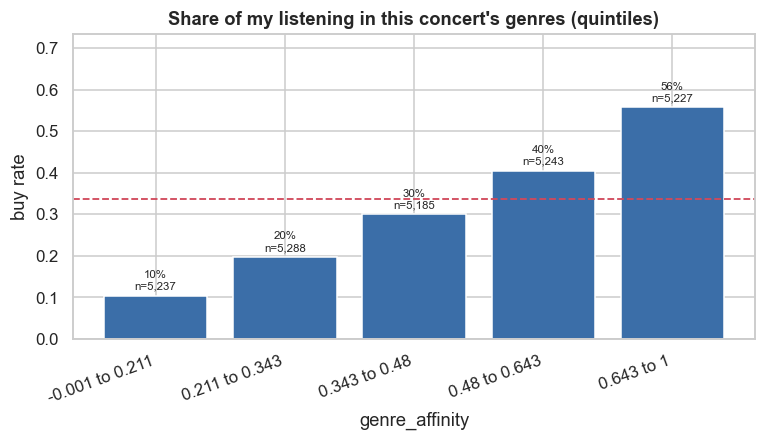

stated favourite genre == most-listened genre for only 35% of users


In [30]:
gshare = pd.crosstab(plays["music_app_user_id"], plays["genre"], normalize="index")
concert_genres = train.drop_duplicates("concert_id").set_index("concert_id")["genres"].str.split("|").to_dict()


def add_genre_features(df):
    df["genre_affinity"] = np.nan
    ok = df["music_app_user_id"].isin(gshare.index)
    for cid, gens in concert_genres.items():
        m = ok & (df["concert_id"] == cid)
        cols = [g for g in gens if g in gshare.columns]
        df.loc[m, "genre_affinity"] = gshare.loc[df.loc[m, "music_app_user_id"], cols].sum(axis=1).values
    df.loc[df["app_status"] == "empty", "genre_affinity"] = 0
    return df


train = add_genre_features(train)
test = add_genre_features(test)
act = train[train["app_status"] == "active"]

top_genre = gshare.idxmax(axis=1)
u = train.drop_duplicates("user_id").dropna(subset=["stated_favourite_genre"])
u = u[u["music_app_user_id"].isin(top_genre.index)]
agree = (u["stated_favourite_genre"].values == top_genre.loc[u["music_app_user_id"]].values).mean()

fig, ax = plt.subplots(figsize=(8, 3.6))
rate_plot(act, "genre_affinity", q=5, ax=ax, title="Share of my listening in this concert's genres (quintiles)", rot=20)
plt.show()
print(f"stated favourite genre == most-listened genre for only {agree:.0%} of users")

> **What I take from this**
> - Genre affinity goes from ~10% to ~56% buy across quintiles. Weaker than the artist-level features but still strong, and it's computed from different plays (the library acts), so it adds information rather than repeating it.
> - The stated favourite genre agrees with what people actually listen to only ~35% of the time. The description warned it's "imperfect", and the listening data is clearly the more reliable version of the same idea.
>
> **→ Feature ideas (listening)**
> - per user × concert artist: `art_plays`, `art_search`, `art_saved`, `art_completion`, `art_skip_rate`, `art_distinct_tracks`, `art_share`, `art_days_since_last`, `art_plays_14d`
> - within user: `art_rank_in_user`, `art_plays_vs_user_max`
> - `genre_affinity` (share of plays in the concert's genres)
> - ideas for later: search share (deliberate / total), a time-decayed play count (recent plays weigh more), saved share, user-level totals (heavy vs light listener)

---
## 11. All signals side by side

Everything above was one column at a time. To compare them on the same scale, I use the **univariate ROC AUC** of each candidate feature: if I sorted rows by this single feature, how well would it separate buyers from non-buyers?

- 0.5 = useless (random ordering), 1.0 = perfect
- I show `max(AUC, 1 − AUC)` so a feature that works "backwards" (like price ratio: higher = less buying) still shows its strength. The colour tells the direction.
- Computed only on rows where the feature isn't blank (the coverage column says how many that is).

This is a quick ranking, not a model: it ignores interactions, so a feature with a low score here can still help in combination.

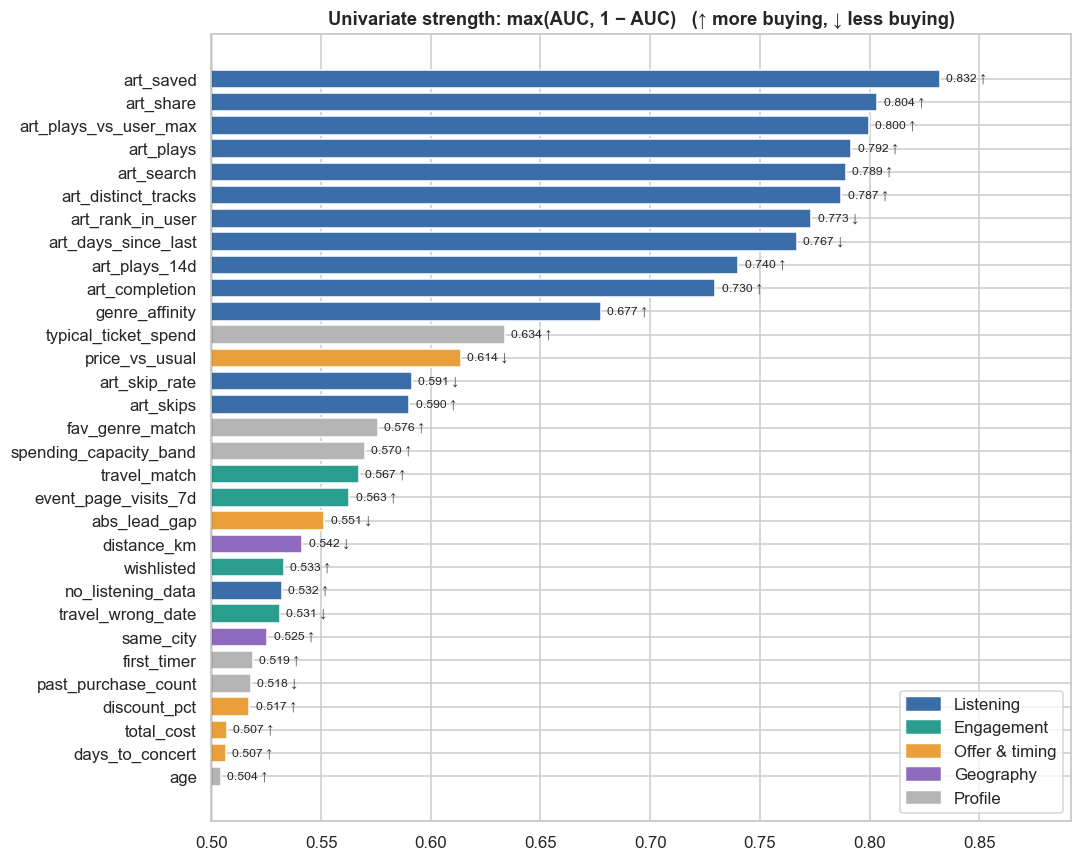

,feature,group,auc,strength,direction,coverage
0,art_saved,Listening,0.832,0.832,higher → more buying,0.912
1,art_share,Listening,0.804,0.804,higher → more buying,0.912
2,art_plays_vs_user_max,Listening,0.800,0.800,higher → more buying,0.873
3,art_plays,Listening,0.792,0.792,higher → more buying,0.912
4,art_search,Listening,0.789,0.789,higher → more buying,0.912
5,art_distinct_tracks,Listening,0.787,0.787,higher → more buying,0.912
6,art_rank_in_user,Listening,0.227,0.773,higher → less buying,0.912
7,art_days_since_last,Listening,0.233,0.767,higher → less buying,0.695
8,art_plays_14d,Listening,0.740,0.740,higher → more buying,0.912
9,art_completion,Listening,0.730,0.730,higher → more buying,0.695


In [31]:
from sklearn.metrics import roc_auc_score

for df in (train, test):
    df["abs_lead_gap"] = df["lead_gap"].abs()
    df["fav_genre_match"] = [np.nan if pd.isna(f) else float(f in g.split("|"))
                             for f, g in zip(df["stated_favourite_genre"], df["genres"])]
    df["travel_match"] = ((df["travel_to_venue"] == 1) & (df["arrival_gap_days"].abs() <= 1)).astype(int)
    df["travel_wrong_date"] = ((df["travel_to_venue"] == 1) & (df["arrival_gap_days"].abs() > 1)).astype(int)
    df["no_listening_data"] = df["app_status"].isin(["missing", "no_app"]).astype(int)

CANDIDATES = {
    "Listening": ["art_plays", "art_search", "art_saved", "art_completion", "art_skips", "art_skip_rate", "art_distinct_tracks",
                  "art_share", "art_days_since_last", "art_plays_14d", "art_rank_in_user", "art_plays_vs_user_max",
                  "genre_affinity", "no_listening_data"],
    "Engagement": ["event_page_visits_7d", "wishlisted", "travel_match", "travel_wrong_date"],
    "Offer & timing": ["total_cost", "discount_pct", "price_vs_usual", "abs_lead_gap", "days_to_concert"],
    "Geography": ["same_city", "distance_km"],
    "Profile": ["typical_ticket_spend", "spending_capacity_band", "first_timer", "past_purchase_count", "age", "fav_genre_match"],
}
res = []
for grp, cols in CANDIDATES.items():
    for c in cols:
        m = train[c].notna()
        auc = roc_auc_score(train.loc[m, "buy"], train.loc[m, c])
        res.append({"feature": c, "group": grp, "auc": auc, "strength": max(auc, 1 - auc),
                    "direction": "higher → more buying" if auc >= 0.5 else "higher → less buying",
                    "coverage": m.mean()})
res = pd.DataFrame(res).sort_values("strength", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 8))
pal = {"Listening": BLUE, "Engagement": GREEN, "Offer & timing": "#e9a03b", "Geography": "#8e6bbf", "Profile": GREY}
ax.barh(res["feature"][::-1], res["strength"][::-1] - 0.5, left=0.5, color=[pal[g] for g in res["group"][::-1]])
for i, (s, d) in enumerate(zip(res["strength"][::-1], res["direction"][::-1])):
    ax.text(s + 0.003, i, f"{s:.3f} {'↑' if d.startswith('higher → more') else '↓'}", va="center", fontsize=8)
ax.axvline(0.5, color="black", lw=0.8)
ax.set_xlim(0.5, res["strength"].max() + 0.06)
ax.set_title("Univariate strength: max(AUC, 1 − AUC)   (↑ more buying, ↓ less buying)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in pal.values()], labels=pal.keys(), loc="lower right")
plt.tight_layout(); plt.show()
res

And a quick look at **redundancy**: features that say the same thing. If two features are almost perfectly correlated, the second one adds little (and for linear models it can make coefficients unstable).

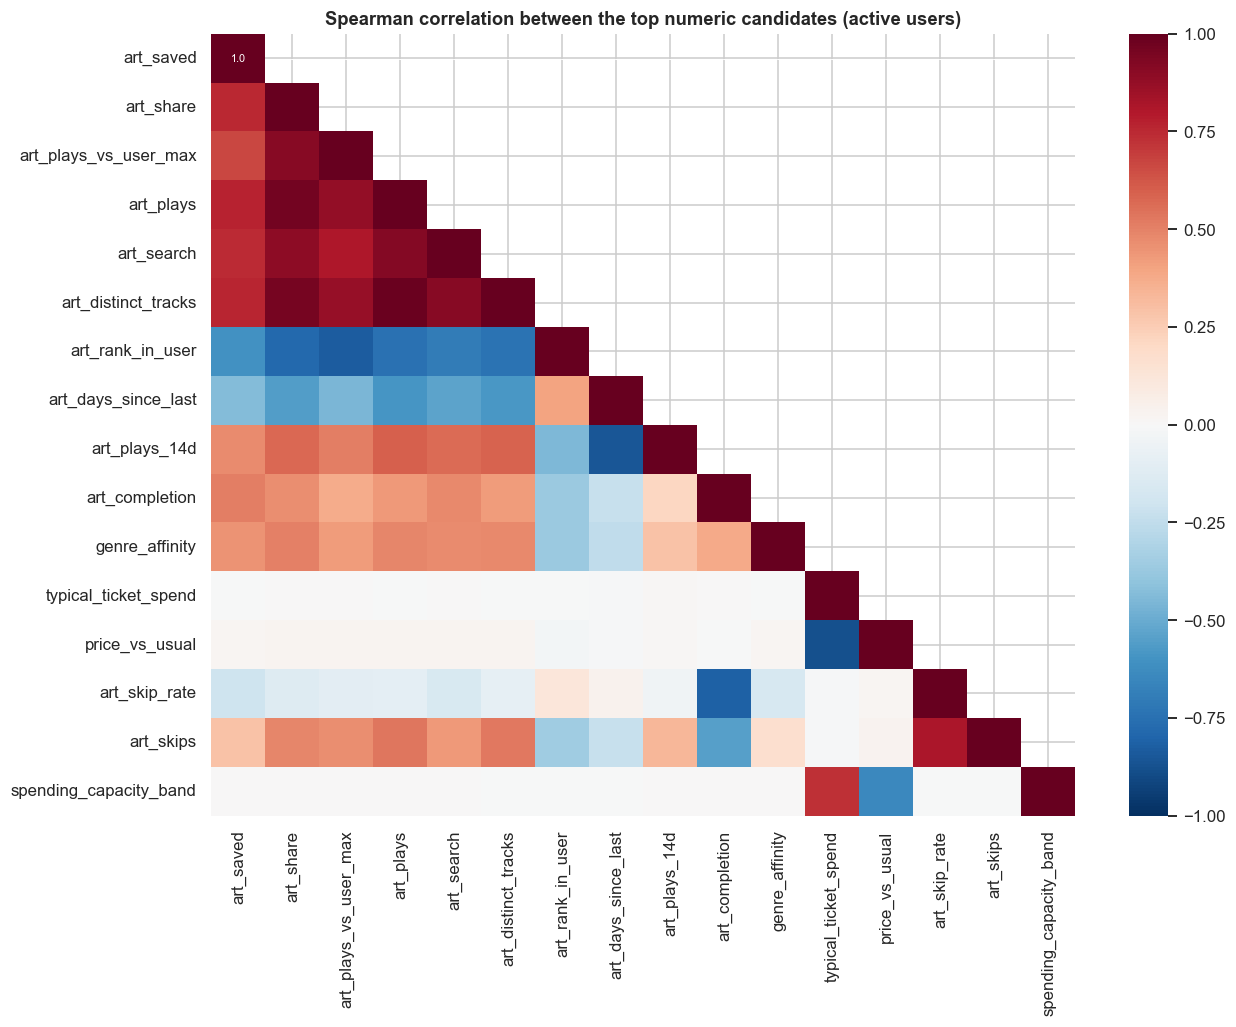

In [32]:
num_cols = [c for c in res["feature"] if train[c].nunique() > 2][:16]
corr = train.loc[train["app_status"] == "active", num_cols].corr(method="spearman")
plt.figure(figsize=(12, 9.5))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f", annot_kws={"size": 7},
            mask=np.triu(np.ones_like(corr, dtype=bool), k=1))
plt.title("Spearman correlation between the top numeric candidates (active users)")
plt.tight_layout(); plt.show()

> **What I take from this**
> - The top 11 are **all listening features** (0.68 to 0.83). `art_saved` is the single best one. Then `typical_ticket_spend` (0.63) and `price_vs_usual` (0.61). The raw profile columns (age, past purchases, total cost...) are at the very bottom, basically 0.50-0.52.
> - Careful how you read this for rare flags: `travel_match` only scores ~0.57 even though it means ~74% buy. That's because it's on for only ~7.6% of rows, and AUC measures how well a feature ranks *all* rows. A rare but very precise flag looks weak here and can still be super useful inside a tree.
> - Fun one: `art_skips` (the raw count) goes in the **"more buying"** direction, because people who play an artist a lot also skip more in absolute terms. The **rate** `art_skip_rate` goes the right way (more skipping → less buying). Counts vs rates matter: always ask "per what?"
> - The artist play counts (plays, search, saved, distinct tracks, share) are strongly correlated with each other. They're different views of "how much of a fan am I". For trees this is fine. For logistic regression we may want to keep only a few, or use regularisation (L1/L2, lecture 3), or try PCA on this block (lecture 2).
> - Rank and recency are still quite correlated with the counts (around −0.6 to −0.8), but not perfectly, so they add some info. `art_plays_14d` and `art_days_since_last` are almost the same thing (−0.9): we probably keep one.
> - `art_completion`, `genre_affinity` (≈0.4-0.5 with the counts) and everything outside the listening block (price, visits, band...) are close to independent from the listening counts. That's what we want: different angles on the same decision.
> - One non-listening pair: `spending_capacity_band` vs `price_vs_usual` is −0.6. Makes sense, richer users find the same ticket relatively cheaper.

---
## 12. Do train and test look the same?

If train and test came from different distributions, our local CV score would not predict the leaderboard. Two checks:

1. compare a few key columns directly
2. **adversarial validation**: a trick Kaggle people use a lot. Mix train and test rows, label them 0 = train / 1 = test, and train a classifier to tell them apart. If it can't (AUC ≈ 0.5), the two sets look the same to a model.

In [33]:
cols_cmp = ["age", "spending_capacity_band", "first_timer", "total_cost", "price_vs_usual", "event_page_visits_7d",
            "wishlisted", "travel_match", "same_city", "art_plays", "art_days_since_last", "genre_affinity"]
cmp = pd.DataFrame({"train_mean": train[cols_cmp].mean(), "test_mean": test[cols_cmp].mean(),
                    "train_missing": train[cols_cmp].isna().mean(), "test_missing": test[cols_cmp].isna().mean()})
display(cmp)

,train_mean,test_mean,train_missing,test_missing
age,41.407,41.792,0.000,0.000
spending_capacity_band,2.979,2.960,0.000,0.000
first_timer,0.275,0.289,0.000,0.000
total_cost,106.459,106.501,0.000,0.000
price_vs_usual,0.956,0.955,0.275,0.289
event_page_visits_7d,0.607,0.616,0.029,0.032
wishlisted,0.162,0.166,0.000,0.000
travel_match,0.076,0.076,0.000,0.000
same_city,0.150,0.148,0.000,0.000
art_plays,3.896,3.878,0.088,0.087


In [33]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

from sklearn.model_selection import GroupKFold

adv_cols = [c for c in res["feature"]] + ["home_lat", "home_lon"]
adv = pd.concat([train[adv_cols + ["user_id"]].assign(is_test=0), test[adv_cols + ["user_id"]].assign(is_test=1)],
                ignore_index=True)
clf = HistGradientBoostingClassifier(max_iter=200, random_state=0)

# version 1: plain stratified folds (rows of the same user can land in different folds)
auc_strat = cross_val_score(clf, adv[adv_cols], adv["is_test"],
                            cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="roc_auc")
# version 2: folds grouped by user (all 5 rows of a user stay together)
auc_group = cross_val_score(clf, adv[adv_cols], adv["is_test"], groups=adv["user_id"],
                            cv=GroupKFold(5), scoring="roc_auc")
print(f"adversarial AUC, StratifiedKFold: {auc_strat.mean():.3f} ± {auc_strat.std():.3f}")
print(f"adversarial AUC, GroupKFold     : {auc_group.mean():.3f} ± {auc_group.std():.3f}")

adversarial AUC, StratifiedKFold: 0.719 ± 0.008
adversarial AUC, GroupKFold     : 0.485 ± 0.007


This one surprised me at first, and I think it's the most useful lesson of the notebook.

With normal stratified folds the classifier gets AUC ≈ 0.61, which would mean "train and test are somewhat different". But with **grouped** folds it drops to ≈ 0.49, i.e. pure guessing.

What happened in version 1: the 5 rows of a user share a lot of user-level values (home city, spending band, typical spend, listening profile...). When some of a user's rows are in the training fold and the others are in the validation fold, the model just **recognises the person** ("I've seen this exact typical spend + band + listening profile, and it was a test user") instead of learning anything about the distributions. That's leakage.

> **What I take from this**
> - Means and missing rates match closely, and with a proper grouped split the adversarial classifier can't tell train from test (AUC ≈ 0.49). Same distribution.
> - The 0.61 vs 0.49 gap is exactly the trap the Kaggle page warns about. If we used plain `KFold` / `StratifiedKFold` for our **real** model, the same "recognise the person" effect would inflate our CV score. **GroupKFold by `user_id`, no exceptions.**
> - So if our local CV is built correctly (grouped by user), it should be a good estimate of the private leaderboard. That's why the Kaggle page tells us to trust local validation over the public leaderboard, which is computed on only ~2,000 users and is noisy.

---
## 13. Summary and feature engineering plan

### What we learned

1. **The unit is user × concert**, 5 rows per user, and test users are all new → `GroupKFold` by `user_id`.
2. **F1 on hard labels** → all-ones gives ~0.50, all-zeros gives 0. The threshold is a hyperparameter we tune on out-of-fold predictions.
3. **Most raw CSV columns are weak, combinations are strong**: price vs usual spend, timing vs usual lead, travel city + date, favourite genre vs concert genres. The exception is money: richer users (spending band, typical spend) buy more.
4. **Listening history is the main source of signal**: never played the artist → ~7%, artist is my #1 → ~69%, last played in the last 3 days → ~70%.
5. **Missing values carry meaning**: no_app / empty / missing ≈ 50% buy vs active ≈ 31%. First-timers have no spend/lead by design.
6. **Train ≈ test** (adversarial AUC ≈ 0.49 with grouped folds), so local CV should be trustworthy, *as long as it's grouped by user* (ungrouped folds leak: 0.61).

### Feature plan

| # | feature | intuition | evidence in this notebook | section |
|---|---|---|---|---|
| 1 | `art_rank_in_user`, `art_plays_vs_user_max` | is this my favourite of the 5? | rank 1 ≈ 69% → rank 5 ≈ 7% | 10.6 |
| 2 | `art_days_since_last`, `art_plays_14d` | is the artist on my mind right now? | ≤3 days ≈ 70% → 2-3 months < 10% | 10.5 |
| 3 | `art_plays`, `art_saved`, `art_search`, `art_share`, `art_distinct_tracks` | how much of a fan am I? | 0 plays ≈ 7%, top bins 85-95%; `art_saved` best single feature (AUC 0.83) | 10.5, 11 |
| 4 | `art_completion`, `art_skip_rate` | do I finish or skip their songs? | completion < 0.3 ≈ 10%; use the skip *rate*, not the count | 10.5, 11 |
| 5 | `genre_affinity` | do I like this kind of music in general? | quintiles ≈ 10% → 56% | 10.7 |
| 6 | `app_status`, `no_listening_data` | missing ≠ no interest | ≈ 50% vs 31% | 10.3 |
| 7 | `travel_match`, `travel_wrong_date` | planning to be there that day? | ≈ 74% vs ≈ 10% | 9 |
| 8 | `event_page_visits_7d`, `wishlisted` | recent interest in this event | both clearly positive | 9 |
| 9 | `price_vs_usual` (+ flag > 1), `typical_ticket_spend` | more expensive than I usually pay? / how big is my budget? | ≈ 40% below, ≈ 19-24% above; still holds within the same spend level | 6, 7 |
| 10 | `abs_lead_gap` | is this week my usual booking moment? | hump, peak near gap 0 | 7 |
| 11 | `total_cost`, `discount_pct` | the deal itself | weak alone | 7 |
| 12 | `same_city`, `distance_km` | easy trip or not? | same city ≈ 41% vs 32% | 8 |
| 13 | `spending_capacity_band`, `first_timer`, `fav_genre_match` | profile | band 25% → 40%; fav genre match 28% → 42% | 6 |
| 14 | `concert_id` | concert-level differences | 28% → 39% across concerts | 4 |

**Probably drop**: `row_id`, `user_id`, `sale_opened_at`, `prediction_at` (constant / IDs), raw `travel_search_*` strings, `artist_name` (same info as `concert_id`), and likely `education`, `home_city`, `age` (no signal alone, can test in ablation).

### Modelling decisions this EDA points to

- **Validation**: 5-fold `GroupKFold(groups=user_id)`, the same fixed split for every experiment.
- **Metric**: track F1 (after threshold tuning) **and** ROC AUC (threshold-free, better to compare models).
- **Missing values**: native NaN for tree models; imputation + missing flags for logistic regression / kNN / SVM.
- **Scaling**: needed for logistic regression, kNN, SVM, PCA (lectures 2-4), not for trees.
- **No outside info** about the real artists (popularity etc.), as the rules say.

